# C07b — RAID-trained RoBERTa-base: OG versus NS10

Fine-tune **FacebookAI/roberta-base** with a new binary classification head on the exact original RAID training split used in C05/C07. This is a RAID-trained RoBERTa detector, not OpenAI's released GPT-2 detector checkpoint. The 54 NS10 texts remain fixed and never enter training, validation, or model selection.

Run from a **fresh kernel** inside the reproduction project. The existing Transformers 4.44.2 environment is supported; no downgrade is necessary. This model is much smaller than Falcon-7B. Microbatch 1, gradient accumulation 16, BF16 mixed precision, and gradient checkpointing are chosen for the 8 GB GPU. Actual peak memory remains hardware/runtime dependent.

Train for three epochs, AdamW learning rate 2e-5, weight decay .01, linear schedule with 10% warmup, unweighted cross-entropy. Save and evaluate every 25 optimizer steps; select the checkpoint with minimum original RAID validation loss. Resume from the last completed checkpoint after interruption (at most 24 optimizer steps replay). Per-document evaluation scores are saved atomically. Keep package versions and output directory unchanged to resume.

Score the first **512 RoBERTa tokens including special tokens**, auditing truncation. Compare all 54 OG/NS10 pairs using the same original validation/test human references and domain weighting as previous stress tests. Native softmax AI scores are not independently calibrated probabilities. Report AUROC, paired changes, validation-calibrated operating points, and one combined staircase. Also report ordinary RAID-test AUROC as a detector sanity check.

Sources: [RoBERTa paper](https://arxiv.org/abs/1907.11692), [base model](https://huggingface.co/FacebookAI/roberta-base), [Transformers 4.44.2 documentation](https://huggingface.co/docs/transformers/v4.44.2/model_doc/roberta).


In [1]:
# Only if missing; keep the working CUDA PyTorch and existing compatible environment.
# %pip install "transformers==4.44.2" "accelerate==0.34.2" huggingface_hub safetensors pandas pyarrow matplotlib scikit-learn tqdm


In [2]:
from pathlib import Path
import os,json,hashlib,tempfile,time,getpass,math
from datetime import datetime,timezone
import numpy as np
import pandas as pd
import requests
import matplotlib.pyplot as plt
from tqdm.auto import tqdm
from sklearn.metrics import roc_curve,auc
from IPython.display import display
ROOT=next((p for p in [Path.cwd().resolve(),*Path.cwd().resolve().parents]
 if (p/'results/causal/C05_Ghostbuster_RAID_fixed54').exists()),None)
assert ROOT is not None,'Run inside the reproduction project.'
BASE=ROOT/'results/causal/C02d2_fz118_ghostbuster_raid'
C05=ROOT/'results/causal/C05_Ghostbuster_RAID_fixed54'
NSDIR=ROOT/'results/causal/C06b_NEW_steps5_10_v1'
OUT=ROOT/'results/causal/C07b_RoBERTa_RAID_OG_NS10_v1'
OUT.mkdir(parents=True,exist_ok=True)
CACHE=OUT/'responses';CACHE.mkdir(exist_ok=True)
SEED=20260922
MODEL_ID='FacebookAI/roberta-base'
MAX_TOKENS=512
EPOCHS=3
BATCH_SIZE=1
ACCUMULATION=16
LR=2e-5
CHECKPOINT_STEPS=25
import gc,random,importlib.metadata
import torch
from transformers import (AutoTokenizer,AutoModelForSequenceClassification,
 DataCollatorWithPadding,Trainer,TrainingArguments,set_seed)
from transformers.trainer_utils import get_last_checkpoint
from huggingface_hub import HfApi
assert torch.cuda.is_available() and torch.cuda.is_bf16_supported(), 'Configured for a BF16-capable CUDA GPU.'
set_seed(SEED)

def text_sha(t):return hashlib.sha256(str(t).encode()).hexdigest()
def file_sha(p):return hashlib.sha256(Path(p).read_bytes()).hexdigest()
def atomic(path,data):
 fd,tmp=tempfile.mkstemp(dir=Path(path).parent,suffix='.tmp')
 try:
  with os.fdopen(fd,'wb') as f:f.write(data);f.flush();os.fsync(f.fileno())
  os.replace(tmp,path)
 finally:
  if os.path.exists(tmp):os.unlink(tmp)
def save_json(obj,p):atomic(p,json.dumps(obj,sort_keys=True,indent=2,allow_nan=False).encode())
def save_csv(df,p):atomic(p,df.to_csv(index=False).encode())
def freeze(obj,p):
 if p.exists():assert json.loads(p.read_text())==obj,'Protocol changed; use a new OUT directory.'
 else:save_json(obj,p)

# Avoid reading a large file wholly into memory when hashing checkpoint weights.
def file_sha(p):
 h=hashlib.sha256()
 with open(p,'rb') as f:
  for chunk in iter(lambda:f.read(1024*1024),b''):h.update(chunk)
 return h.hexdigest()


/home/user/Downloads/TemporalContextResearch/.venv/lib/python3.12/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


In [3]:
# Resolve the exact C05 data universe through saved doc keys.
meta=pd.read_parquet(BASE/'fz118_paired_features.parquet')
corpus=pd.read_parquet(BASE/'paired_corpus.parquet')
assert meta.source_id.is_unique and corpus.source_id.is_unique
raid=meta.loc[meta.dataset.eq('raid'),['source_id','split','label','domain']].copy().reset_index(drop=True)
keys=pd.read_parquet(C05/'raid_all_features.parquet',columns=['doc_key']).doc_key
expected='raid::'+raid.source_id.astype(str)
assert keys.is_unique and set(keys)==set(expected), 'C05 dataset mismatch'
raid['text']=raid.source_id.map(corpus.set_index('source_id').text)
assert raid.text.notna().all() and raid.text.astype(str).str.strip().ne('').all()
assert set(raid.split)=={'train','validation','test'}
ns=pd.read_csv(NSDIR/'NS10_texts.csv',keep_default_na=False).sort_values('case_id').reset_index(drop=True)
assert len(ns)==54 and ns.case_id.is_unique and ns.source_id.is_unique
assert ns.text.map(text_sha).eq(ns.text_sha).all()
rm=raid.set_index('source_id')
assert rm.loc[ns.source_id,'split'].eq('test').all()
assert rm.loc[ns.source_id,'label'].eq(1).all()
assert rm.loc[ns.source_id,'domain'].tolist()==ns.domain.tolist()
og=ns[['case_id','source_id','domain']].copy();og['text']=og.source_id.map(rm.text)

raid['pair_group_id']=raid.source_id.str.split('__',n=1).str[-1]
assert raid.groupby('pair_group_id').split.nunique().eq(1).all(), 'Source-group split leakage'
raid['text_sha']=raid.text.map(text_sha)
assert raid.groupby('text_sha').split.nunique().eq(1).all(), 'Identical text spans multiple splits'
tr=raid.loc[raid.split.eq('train')].sort_values('source_id').reset_index(drop=True)
va=raid.loc[raid.split.eq('validation')].sort_values('source_id').reset_index(drop=True)
assert tr.label.nunique()==va.label.nunique()==2
save_csv(raid.drop(columns='text'),OUT/'RAID_manifest.csv')
save_csv(ns[['case_id','source_id','domain','text_sha']],OUT/'NS10_manifest.csv')
display(raid.groupby(['split','label']).size().rename('n').to_frame())
print('All 54 NS10 pairs resolve to original RAID test AI; no attack fitting.')

assert not set(ns.text_sha)&set(pd.concat([tr,va]).text_sha), 'NS10 text overlaps training/validation.'
# Preserve the exact original splits, including all labels for training/validation.
del meta,corpus,rm,keys,expected
gc.collect()


n
split      label     
test       0      138
           1      138
train      0      636
           1      636
validation 0      135
           1      135

All 54 NS10 pairs resolve to original RAID test AI; no attack fitting.


20

In [4]:
revpath=OUT/'model_revision.json'
if revpath.exists():revision=json.loads(revpath.read_text())['revision']
else:
 revision=HfApi().model_info(MODEL_ID).sha;save_json(dict(model=MODEL_ID,revision=revision),revpath)
contract=dict(version='C07b_RoBERTa_v1',model=MODEL_ID,revision=revision,seed=SEED,
 max_tokens=MAX_TOKENS,epochs=EPOCHS,microbatch=BATCH_SIZE,accumulation=ACCUMULATION,
 lr=LR,weight_decay=.01,warmup_ratio=.1,scheduler='linear',loss='unweighted_cross_entropy',
 checkpoint_steps=CHECKPOINT_STEPS,selection='minimum_original_RAID_validation_loss',
 precision='fp32_parameters_bf16_autocast',gradient_checkpointing=True,attention='eager',
 runtime={p:importlib.metadata.version(p) for p in ['torch','transformers','accelerate']},
 inputs={str(p.relative_to(ROOT)):file_sha(p) for p in [BASE/'fz118_paired_features.parquet',
 BASE/'paired_corpus.parquet',C05/'raid_all_features.parquet',NSDIR/'NS10_texts.csv']})
freeze(contract,OUT/'contract.json');signature=text_sha(json.dumps(contract,sort_keys=True))
tok=AutoTokenizer.from_pretrained(MODEL_ID,revision=revision)
tok.truncation_side='right'
class TextDataset(torch.utils.data.Dataset):
 def __init__(self,frame):
  self.enc=tok(frame.text.astype(str).tolist(),truncation=True,max_length=MAX_TOKENS)
  self.labels=frame.label.astype(int).tolist()
 def __len__(self):return len(self.labels)
 def __getitem__(self,i):return {**{k:v[i] for k,v in self.enc.items()},'labels':self.labels[i]}
train_data=TextDataset(tr);val_data=TextDataset(va)
# Include ordinary RAID test AI as an independent detector performance audit.
test=raid.loc[raid.split.eq('test')].copy()
h=raid.loc[raid.label.eq(0)&raid.split.isin(['validation','test'])].assign(stage='Human',case_id='')
o=og.assign(stage='OG',split='test',label=1)
n=ns[['case_id','source_id','domain','text']].assign(stage='NS10',split='test',label=1)
regular=test.loc[test.label.eq(1)].assign(stage='RAID_test_AI',case_id='')
docs=pd.concat([h,o,n,regular],ignore_index=True)
docs['text_sha']=docs.text.map(text_sha)
lengths={r.text_sha:len(tok(r.text,truncation=False)['input_ids']) for r in docs.drop_duplicates('text_sha').itertuples()}
docs['total_tokens']=docs.text_sha.map(lengths);docs['truncated']=docs.total_tokens.gt(MAX_TOKENS)
docs['scored_tokens']=docs.total_tokens.clip(upper=MAX_TOKENS)
save_csv(docs.drop(columns='text'),OUT/'score_manifest.csv')
display(docs.groupby('stage').agg(documents=('text_sha','size'),truncated=('truncated','sum')))


/home/user/Downloads/TemporalContextResearch/.venv/lib/python3.12/site-packages/transformers/tokenization_utils_base.py:1601: FutureWarning: `clean_up_tokenization_spaces` was not set. It will be set to `True` by default. This behavior will be depracted in transformers v4.45, and will be then set to `False` by default. For more details check this issue: https://github.com/huggingface/transformers/issues/31884
  warnings.warn(
Token indices sequence length is longer than the specified maximum sequence length for this model (552 > 512). Running this sequence through the model will result in indexing errors


,documents,truncated
stage,,
Human,273,9
NS10,54,25
OG,54,1
RAID_test_AI,138,3


In [5]:
# Full-model fine-tuning; caches and Trainer checkpoints are separate.
TRAIN_DIR=OUT/'training';TRAIN_DIR.mkdir(exist_ok=True)
BEST=OUT/'best_model';DONE=OUT/'training_complete.json'
if DONE.exists():
 done=json.loads(DONE.read_text());assert done['contract']==signature
 assert (BEST/'config.json').exists()
 model=AutoModelForSequenceClassification.from_pretrained(BEST,attn_implementation='eager').to('cuda')
 print('Using saved selected detector.')
else:
 set_seed(SEED)
 model=AutoModelForSequenceClassification.from_pretrained(MODEL_ID,revision=revision,
  num_labels=2,id2label={0:'Human',1:'AI'},label2id={'Human':0,'AI':1},attn_implementation='eager')
 # A newly initialized classification head is expected and is trained below.
 args=TrainingArguments(output_dir=str(TRAIN_DIR),num_train_epochs=EPOCHS,
  per_device_train_batch_size=BATCH_SIZE,per_device_eval_batch_size=2,
  gradient_accumulation_steps=ACCUMULATION,learning_rate=LR,weight_decay=.01,
  warmup_ratio=.1,lr_scheduler_type='linear',optim='adamw_torch',max_grad_norm=1.0,
  bf16=True,fp16=False,gradient_checkpointing=True,
  gradient_checkpointing_kwargs={'use_reentrant':False},
  eval_strategy='steps',eval_steps=CHECKPOINT_STEPS,save_strategy='steps',save_steps=CHECKPOINT_STEPS,
  save_total_limit=2,load_best_model_at_end=True,metric_for_best_model='eval_loss',greater_is_better=False,
  logging_steps=10,report_to=[],seed=SEED,data_seed=SEED,dataloader_num_workers=0,
  dataloader_pin_memory=False,eval_accumulation_steps=16,save_safetensors=True)
 trainer=Trainer(model=model,args=args,train_dataset=train_data,eval_dataset=val_data,
  data_collator=DataCollatorWithPadding(tok,pad_to_multiple_of=8),tokenizer=tok)
 last=get_last_checkpoint(str(TRAIN_DIR))
 print('Resume checkpoint:',last or 'new training',flush=True)
 trainer.train(resume_from_checkpoint=last)
 trainer.save_model(str(BEST));tok.save_pretrained(BEST)
 save_json(trainer.state.log_history,OUT/'training_log.json')
 save_json(dict(contract=signature,best_checkpoint=trainer.state.best_model_checkpoint,
  best_validation_loss=float(trainer.state.best_metric),global_step=trainer.state.global_step),DONE)
 # Trainer loads the selected best checkpoint before saving above.
 model=trainer.model
 del trainer;gc.collect();torch.cuda.empty_cache()
model.eval()
weights=sorted(BEST.glob('*.safetensors')) or sorted(BEST.glob('pytorch_model*.bin'))
assert weights,'Missing selected checkpoint weights'
model_digest=text_sha(json.dumps({p.name:file_sha(p) for p in weights},sort_keys=True))
score_signature=text_sha(signature+model_digest)
print('Selected detector ready. No NS10 examples used for fitting or selection.')


Some weights of RobertaForSequenceClassification were not initialized from the model checkpoint at FacebookAI/roberta-base and are newly initialized: ['classifier.dense.bias', 'classifier.dense.weight', 'classifier.out_proj.bias', 'classifier.out_proj.weight']
You should probably TRAIN this model on a down-stream task to be able to use it for predictions and inference.


Resume checkpoint: new training


Step,Training Loss,Validation Loss
25,0.680200,0.641406
50,0.251900,0.520455
75,0.168000,0.175204
100,0.082100,0.150643
125,0.124200,0.199899
150,0.152300,0.265350
175,0.043800,0.366710
200,0.003700,0.178359
225,0.038400,0.250723


Selected detector ready. No NS10 examples used for fitting or selection.


In [6]:
def score_path(sha):return CACHE/(text_sha(score_signature+sha)+'.json')
unique=docs[['text_sha','text']].drop_duplicates('text_sha')
for r in tqdm(unique.itertuples(index=False),total=len(unique),desc='RoBERTa scoring'):
 path=score_path(r.text_sha)
 if path.exists():
  record=json.loads(path.read_text())
  assert record['score_contract']==score_signature and record['text_sha']==r.text_sha
  continue
 enc=tok(r.text,return_tensors='pt',truncation=True,max_length=MAX_TOKENS).to('cuda')
 with torch.inference_mode(),torch.autocast('cuda',dtype=torch.bfloat16):logits=model(**enc).logits
 ai=float(logits.float().softmax(-1)[0,1].cpu())
 assert np.isfinite(ai) and 0<=ai<=1
 save_json(dict(text_sha=r.text_sha,score_contract=score_signature,AI_score=ai),path)
records=[]
for row in docs.drop(columns='text').to_dict('records'):
 record=json.loads(score_path(row['text_sha']).read_text())
 assert record['score_contract']==score_signature
 records.append({**row,'AI_score':record['AI_score']})
scored=pd.DataFrame(records);save_csv(scored,OUT/'all_scores.csv')
O=scored.loc[scored.stage.eq('OG')];N=scored.loc[scored.stage.eq('NS10')];R=scored.loc[scored.stage.eq('Human')]
paired=O[['case_id','source_id','domain','AI_score']].rename(columns={'AI_score':'OG_AI_score'}).merge(
 N[['case_id','source_id','AI_score']].rename(columns={'AI_score':'NS10_AI_score'}),
 on=['case_id','source_id'],validate='one_to_one')
assert len(paired)==54
save_csv(paired,OUT/'paired_scores.csv')
# Ordinary RAID-test sanity check, empirical class/genre distribution.
from sklearn.metrics import roc_auc_score
regular_scores=pd.concat([scored.loc[scored.stage.eq('Human')&scored.split.eq('test')],
 scored.loc[scored.stage.eq('RAID_test_AI')]],ignore_index=True)
regular_summary=pd.DataFrame([dict(cases=len(regular_scores),AUROC=roc_auc_score(regular_scores.label,regular_scores.AI_score))])
save_csv(regular_summary,OUT/'regular_RAID_test_summary.csv');display(regular_summary)


RoBERTa scoring: 100%|██████████████████████████████████████████████████████████████████████████| 465/465 [00:05<00:00, 82.04it/s]


,cases,AUROC
0,276,0.98871


In [7]:
mix=paired.domain.value_counts(normalize=True)
def humans(split):
    q=R.loc[R.split.eq(split)&R.label.eq(0)&R.domain.isin(mix.index)].copy()
    counts=q.domain.value_counts();assert set(mix.index)<=set(counts.index)
    q['weight']=[mix[d]/counts[d] for d in q.domain]
    assert np.isclose(q.weight.sum(),1)
    save_csv(q,OUT/(split+'_human_reference.csv'));return q
cal=humans('validation');human=humans('test')
cuts=np.r_[np.inf,np.unique(cal.AI_score)[::-1],-np.inf]
st=pd.DataFrame(dict(threshold=cuts,
    calibration_FPR=[cal.loc[cal.AI_score>c,'weight'].sum() for c in cuts],
    test_FPR=[human.loc[human.AI_score>c,'weight'].sum() for c in cuts]))
rows=[]
for name in ['OG','NS10']:
    ai=paired[name+'_AI_score'].to_numpy();hs=human.AI_score.to_numpy()
    fpr,tpr,_=roc_curve(np.r_[np.zeros(len(hs)),np.ones(len(ai))],np.r_[hs,ai],
        sample_weight=np.r_[human.weight,np.ones(len(ai))/len(ai)],drop_intermediate=False)
    rows.append(dict(stage=name,cases=len(ai),AUROC=auc(fpr,tpr),mean_AI_score=ai.mean(),median_AI_score=np.median(ai)))
    st[name]=[(ai>c).mean() for c in cuts]
summary=pd.DataFrame(rows);display(summary.round(6))
save_csv(summary,OUT/'stage_summary.csv');save_csv(st,OUT/'C07b_TPR_staircase.csv')
# Conservative validation-human thresholds; report realized test FPR explicitly.
operating=[]
for target in [0,.001,.005,.01,.02,.05,.1,.2,.5,1.]:
    eligible=st.loc[st.calibration_FPR<=target+1e-12]
    row=eligible.iloc[-1].to_dict();row['target_FPR']=target;operating.append(row)
operating=pd.DataFrame(operating)
save_csv(operating,OUT/'operating_points.csv');display(operating)

# Paired AUROC change against the fixed, genre-weighted human reference.
# Each AI observation contributes its probability of outranking a human (ties half).
hs=human.AI_score.to_numpy();hw=human.weight.to_numpy()
def auc_contributions(scores):
    a=np.asarray(scores)[:,None];return (((a>hs)+.5*(a==hs))*hw).sum(axis=1)
d=auc_contributions(paired.NS10_AI_score)-auc_contributions(paired.OG_AI_score)
rng=np.random.default_rng(SEED);ix=rng.integers(0,len(paired),size=(10000,len(paired)))
changes=[]
for metric,v in [('AUROC',d),('AI_score',(paired.NS10_AI_score-paired.OG_AI_score).to_numpy())]:
    lo,hi=np.quantile(v[ix].mean(axis=1),[.025,.975])
    changes.append(dict(metric=metric,comparison='NS10_minus_OG',cases=len(paired),mean_delta=v.mean(),
                        ci_low=lo,ci_high=hi,increased=int((v>0).sum()),decreased=int((v<0).sum())))
changes=pd.DataFrame(changes);save_csv(changes,OUT/'paired_changes.csv');display(changes)
print('Intervals resample paired cases with fixed human reference; they exclude training-seed uncertainty.')


,stage,cases,AUROC,mean_AI_score,median_AI_score
0,OG,54,0.991550,0.943297,0.998190
1,NS10,54,0.732803,0.174755,0.022628


,threshold,calibration_FPR,test_FPR,OG,NS10,target_FPR
0,0.695131,0.000000,0.015138,0.944444,0.111111,0.000
1,0.695131,0.000000,0.015138,0.944444,0.111111,0.001
2,0.537770,0.003086,0.022340,0.944444,0.129630,0.005
3,0.537770,0.003086,0.022340,0.944444,0.129630,0.010
4,0.067547,0.018148,0.067864,0.962963,0.351852,0.020
5,0.036494,0.049218,0.077895,0.962963,0.425926,0.050
6,0.022803,0.096319,0.102384,0.962963,0.500000,0.100
7,0.014282,0.185965,0.201893,1.000000,0.629630,0.200
8,0.010489,0.494421,0.504422,1.000000,0.722222,0.500
9,-inf,1.000000,1.000000,1.000000,1.000000,1.000


,metric,comparison,cases,mean_delta,ci_low,ci_high,increased,decreased
0,AUROC,NS10_minus_OG,54,-0.258747,-0.336115,-0.185447,1,50
1,AI_score,NS10_minus_OG,54,-0.768542,-0.856737,-0.669053,1,53


Intervals resample paired cases with fixed human reference; they exclude training-seed uncertainty.


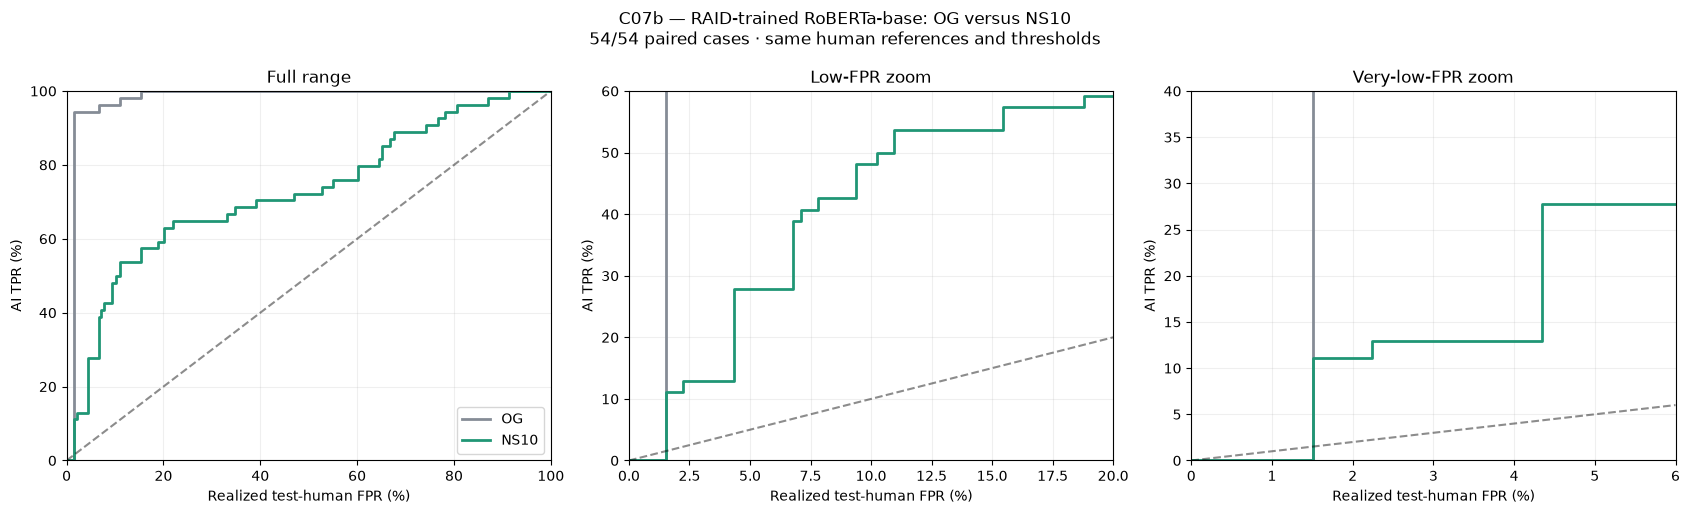

Saved all scores, thresholds, paired comparisons and figures: ../results/causal/C07b_RoBERTa_RAID_OG_NS10_v1
NS10 was excluded from detector training, validation selection and calibration.


In [8]:
COLORS={'OG':'#858C96','NS10':'#209675'}
def save_figure(fig,stem):
    for folder in [OUT,ROOT/'figures']:
        folder.mkdir(exist_ok=True,parents=True)
        for ext in ['png','pdf']:fig.savefig(folder/(stem+'.'+ext),dpi=300,bbox_inches='tight')
    plt.show();plt.close(fig)
fig,axs=plt.subplots(1,3,figsize=(17,5.2))
for ax,(xl,yl,title) in zip(axs,[((0,100),(0,100),'Full range'),((0,20),(0,60),'Low-FPR zoom'),((0,6),(0,40),'Very-low-FPR zoom')]):
    for name in COLORS:ax.step(st.test_FPR*100,st[name]*100,where='post',color=COLORS[name],lw=2,label=name)
    hi=min(xl[1],yl[1]);ax.plot([0,hi],[0,hi],'--',color='black',alpha=.45)
    ax.set(xlim=xl,ylim=yl,title=title,xlabel='Realized test-human FPR (%)',ylabel='AI TPR (%)');ax.grid(alpha=.2)
axs[0].legend()
fig.suptitle(f'C07b — RAID-trained RoBERTa-base: OG versus NS10\n{len(paired)}/54 paired cases · same human references and thresholds')
fig.tight_layout();save_figure(fig,'C07b_RoBERTa_OG_NS10_TPR_staircase')


print('Saved all scores, thresholds, paired comparisons and figures:',OUT)
print('NS10 was excluded from detector training, validation selection and calibration.')


## Reporting

Report this as **RAID-trained RoBERTa-base**, with the frozen source split, checkpoint-selection protocol, precision, prefix truncation, and full 54-case paired comparison. This is attack transfer: the existing NS10 texts are never changed using RoBERTa feedback. Human text appears only in defender fitting/evaluation.

The staircase uses validation-derived thresholds and shows realized test FPR; AUROC uses all test thresholds. Pair-bootstrap intervals hold the human reference and selected detector fixed and exclude training-seed uncertainty. Do not claim equivalence with OpenAI's released detector or other RoBERTa training protocols. No adaptive fine-tuning is included in this initial run.

Saved artifacts: selected model, resumable Trainer checkpoints, protocol and split manifests, per-text scores, ordinary RAID-test sanity check, paired summaries, thresholds, and PNG/PDF figures. Numerical training/inference must be executed on your machine; notebook preparation validates structure and evaluation logic, not empirical detector performance.


Adaptation resume checkpoint: new adaptation


Step,Training Loss,Validation Loss
25,0.062700,0.268788
50,0.184400,0.234549
75,0.104200,0.199814
100,0.105400,0.181792
125,0.015700,0.197519
150,0.075000,0.371708
175,0.060500,0.166734
200,0.012500,0.191455
225,0.047600,0.259884


Adapted RoBERTa scoring: 100%|██████████████████████████████████████████████████████████████████| 307/307 [00:03<00:00, 84.27it/s]


,detector,cases,AUROC,mean_AI_score,median_AI_score
0,Frozen,34,0.729107,0.186319,0.027068
1,Adapted,34,0.965662,0.876828,0.998412


,detector,threshold,calibration_FPR,test_FPR,TPR,target_FPR
3,Frozen,0.537770,0.004902,0.023343,0.147059,0.01
5,Frozen,0.042088,0.044771,0.079715,0.441176,0.05
6,Frozen,0.024988,0.099346,0.105257,0.529412,0.10
13,Adapted,0.973645,0.005882,0.036415,0.764706,0.01
15,Adapted,0.072637,0.046732,0.051937,0.911765,0.05
16,Adapted,0.011687,0.099486,0.090715,0.941176,0.10


,metric,comparison,cases,mean_delta,ci_low,ci_high,increased,decreased,unchanged
0,AUROC,Adapted_minus_Frozen,34,0.236555,0.151681,0.328964,33,0,1
1,AI_score,Adapted_minus_Frozen,34,0.690509,0.562961,0.804832,32,2,0


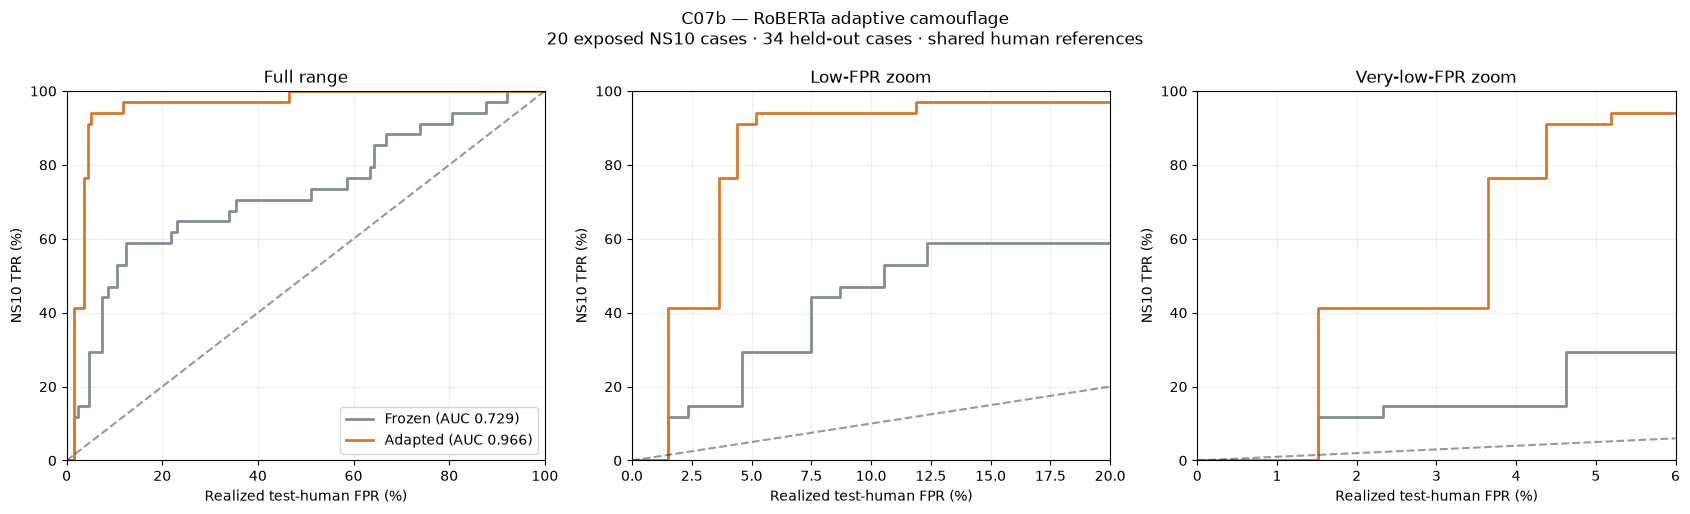

Saved: ../results/causal/C07b_RoBERTa_RAID_OG_NS10_v1/adaptation20_34_seed20260923
Compare adapted with the frozen 34-case baseline above, not the 54-case result.
Intervals condition on this split, fitted detectors, and fixed human references.


In [9]:
# C07b — adaptive camouflage: 20 exposed NS10 / 34 held out
# Uses the existing notebook's data, helpers, tokenizer and selected BEST model.
import gc
from sklearn.metrics import roc_auc_score

ADAPT_SEED = 20260923
ADAPT_EPOCHS = 3
ADAPT_LR = 1e-5
AD = OUT / "adaptation20_34_seed20260923"
AD.mkdir(parents=True, exist_ok=True)
AD_TRAIN = AD / "training"
AD_BEST = AD / "best_model"
AD_DONE = AD / "training_complete.json"
AD_CACHE = AD / "scores"
AD_CACHE.mkdir(exist_ok=True)

assert len(ns) == 54 and ns.case_id.is_unique
assert (BEST / "config.json").exists(), "Finish the original detector training first."

# Freeze the random exposure split before fitting.
ids = sorted(ns.case_id.astype(str).tolist())
exposed = sorted(
    np.random.default_rng(ADAPT_SEED).choice(ids, 20, replace=False).tolist()
)
heldout = sorted(set(ids) - set(exposed))
freeze(
    dict(seed=ADAPT_SEED, adaptation_cases=exposed, test_cases=heldout),
    AD / "split.json",
)
roles = ns[["case_id", "source_id", "domain", "text_sha"]].copy()
roles["role"] = np.where(roles.case_id.isin(exposed), "adaptation", "test")
save_csv(roles, AD / "case_roles.csv")

exposure = ns.loc[ns.case_id.isin(exposed)].copy()
exposure["label"] = 1
attack_test = ns.loc[ns.case_id.isin(heldout)].sort_values("case_id").copy()
fit = pd.concat(
    [tr[["text", "label"]], exposure[["text", "label"]]],
    ignore_index=True,
)
assert len(exposure) == 20 and len(attack_test) == 34
assert not set(fit.text.map(text_sha)) & set(attack_test.text_sha)
assert not set(fit.text.map(text_sha)) & set(va.text_sha)

base_weights = sorted(BEST.glob("*.safetensors")) or sorted(
    BEST.glob("pytorch_model*.bin")
)
assert base_weights
base_digest = text_sha(
    json.dumps({p.name: file_sha(p) for p in base_weights}, sort_keys=True)
)
adapt_protocol = dict(
    version="C07b_adaptation_v1",
    base_contract=signature,
    base_weights=base_digest,
    seed=ADAPT_SEED,
    adaptation_cases=exposed,
    test_cases=heldout,
    training_rows=len(fit),
    epochs=ADAPT_EPOCHS,
    learning_rate=ADAPT_LR,
    microbatch=BATCH_SIZE,
    accumulation=ACCUMULATION,
    max_tokens=MAX_TOKENS,
    checkpoint_steps=CHECKPOINT_STEPS,
    weight_decay=0.01,
    warmup_ratio=0.1,
    scheduler="linear",
    loss="unweighted_cross_entropy",
    selection="minimum_original_RAID_validation_loss",
    all_parameters_trainable=True,
    runtime={
        p: importlib.metadata.version(p)
        for p in ["torch", "transformers", "accelerate"]
    },
)
freeze(adapt_protocol, AD / "protocol.json")
adapt_signature = text_sha(json.dumps(adapt_protocol, sort_keys=True))

# Reuse frozen scores; do not keep two detectors in GPU memory.
frozen_scores = pd.read_csv(OUT / "all_scores.csv", keep_default_na=False)
for variable in ("trainer", "model", "adapt_trainer", "adapt_model"):
    globals().pop(variable, None)
gc.collect()
torch.cuda.empty_cache()

if AD_DONE.exists():
    saved = json.loads(AD_DONE.read_text())
    assert saved["contract"] == adapt_signature
    adapt_model = AutoModelForSequenceClassification.from_pretrained(
        AD_BEST, attn_implementation="eager"
    ).to("cuda")
    print("Using saved adapted detector.")
else:
    set_seed(ADAPT_SEED)
    adapt_model = AutoModelForSequenceClassification.from_pretrained(
        BEST, attn_implementation="eager"
    )
    for parameter in adapt_model.parameters():
        parameter.requires_grad_(True)

    adapt_args = TrainingArguments(
        output_dir=str(AD_TRAIN),
        num_train_epochs=ADAPT_EPOCHS,
        per_device_train_batch_size=BATCH_SIZE,
        per_device_eval_batch_size=2,
        gradient_accumulation_steps=ACCUMULATION,
        learning_rate=ADAPT_LR,
        weight_decay=0.01,
        warmup_ratio=0.1,
        lr_scheduler_type="linear",
        optim="adamw_torch",
        max_grad_norm=1.0,
        bf16=True,
        fp16=False,
        gradient_checkpointing=True,
        gradient_checkpointing_kwargs={"use_reentrant": False},
        eval_strategy="steps",
        eval_steps=CHECKPOINT_STEPS,
        save_strategy="steps",
        save_steps=CHECKPOINT_STEPS,
        save_total_limit=2,
        load_best_model_at_end=True,
        metric_for_best_model="eval_loss",
        greater_is_better=False,
        logging_steps=10,
        report_to=[],
        seed=ADAPT_SEED,
        data_seed=ADAPT_SEED,
        dataloader_num_workers=0,
        dataloader_pin_memory=False,
        eval_accumulation_steps=16,
        save_safetensors=True,
    )
    adapt_trainer = Trainer(
        model=adapt_model,
        args=adapt_args,
        train_dataset=TextDataset(fit),
        eval_dataset=TextDataset(va),
        data_collator=DataCollatorWithPadding(tok, pad_to_multiple_of=8),
        tokenizer=tok,
    )
    last = (
        get_last_checkpoint(str(AD_TRAIN))
        if AD_TRAIN.exists()
        else None
    )
    print("Adaptation resume checkpoint:", last or "new adaptation", flush=True)
    adapt_trainer.train(resume_from_checkpoint=last)
    adapt_trainer.save_model(str(AD_BEST))
    tok.save_pretrained(AD_BEST)
    save_json(adapt_trainer.state.log_history, AD / "training_log.json")
    save_json(
        dict(
            contract=adapt_signature,
            best_checkpoint=adapt_trainer.state.best_model_checkpoint,
            best_validation_loss=float(adapt_trainer.state.best_metric),
            global_step=adapt_trainer.state.global_step,
        ),
        AD_DONE,
    )
    adapt_model = adapt_trainer.model
    del adapt_trainer
    gc.collect()
    torch.cuda.empty_cache()

adapt_model.eval()
adapt_weights = sorted(AD_BEST.glob("*.safetensors")) or sorted(
    AD_BEST.glob("pytorch_model*.bin")
)
assert adapt_weights
adapt_digest = text_sha(
    json.dumps({p.name: file_sha(p) for p in adapt_weights}, sort_keys=True)
)
adapt_score_signature = text_sha(adapt_signature + adapt_digest)

# Same held-out attack texts and human references for both detectors.
eval_docs = docs.loc[
    docs.stage.eq("Human")
    | (docs.stage.eq("NS10") & docs.case_id.isin(heldout))
].copy()

assert not set(fit.text.map(text_sha)) & set(eval_docs.text_sha), (
    "Exact text overlap between adaptation fitting and evaluation."
)

for row in tqdm(
    eval_docs.drop_duplicates("text_sha").itertuples(index=False),
    desc="Adapted RoBERTa scoring",
    total=eval_docs.text_sha.nunique(),
):
    path = AD_CACHE / (
        text_sha(adapt_score_signature + row.text_sha) + ".json"
    )
    if path.exists():
        record = json.loads(path.read_text())
        assert record["contract"] == adapt_score_signature
        assert record["text_sha"] == row.text_sha
        continue

    encoded = tok(
        row.text,
        return_tensors="pt",
        truncation=True,
        max_length=MAX_TOKENS,
    ).to("cuda")
    with torch.inference_mode(), torch.autocast("cuda", dtype=torch.bfloat16):
        logits = adapt_model(**encoded).logits
    score = float(logits.float().softmax(-1)[0, 1].cpu())
    assert np.isfinite(score) and 0 <= score <= 1
    save_json(
        dict(
            contract=adapt_score_signature,
            text_sha=row.text_sha,
            AI_score=score,
        ),
        path,
    )

score_map = {}
for sha in eval_docs.text_sha.unique():
    path = AD_CACHE / (text_sha(adapt_score_signature + sha) + ".json")
    score_map[sha] = json.loads(path.read_text())["AI_score"]

comparison = eval_docs.drop(columns="text").merge(
    frozen_scores[
        ["stage", "source_id", "text_sha", "AI_score"]
    ].rename(columns={"AI_score": "Frozen"}),
    on=["stage", "source_id", "text_sha"],
    validate="one_to_one",
)
assert len(comparison) == len(eval_docs)
comparison["Adapted"] = comparison.text_sha.map(score_map)
assert comparison[["Frozen", "Adapted"]].notna().all().all()
save_csv(comparison, AD / "all_comparison_scores.csv")

attack = comparison.loc[comparison.stage.eq("NS10")].sort_values("case_id")
assert len(attack) == 34
mix = attack.domain.value_counts(normalize=True)

def adaptation_humans(split):
    frame = comparison.loc[
        comparison.stage.eq("Human")
        & comparison.split.eq(split)
        & comparison.domain.isin(mix.index)
    ].copy()
    counts = frame.domain.value_counts()
    assert set(mix.index) <= set(counts.index)
    frame["weight"] = [mix[d] / counts[d] for d in frame.domain]
    assert np.isclose(frame.weight.sum(), 1)
    save_csv(frame, AD / f"{split}_human_reference.csv")
    return frame

validation_humans = adaptation_humans("validation")
test_humans = adaptation_humans("test")
summaries, staircases, operating_rows = [], [], []
contributions = {}

for name in ["Frozen", "Adapted"]:
    ai = attack[name].to_numpy()
    human = test_humans[name].to_numpy()
    human_weights = test_humans.weight.to_numpy()
    validation = validation_humans[name].to_numpy()

    contributions[name] = (
        ((ai[:, None] > human) + 0.5 * (ai[:, None] == human))
        * human_weights
    ).sum(axis=1)
    summaries.append(
        dict(
            detector=name,
            cases=len(ai),
            AUROC=contributions[name].mean(),
            mean_AI_score=ai.mean(),
            median_AI_score=np.median(ai),
        )
    )
    cuts = np.r_[np.inf, np.unique(validation)[::-1], -np.inf]
    staircase = pd.DataFrame(
        dict(
            detector=name,
            threshold=cuts,
            calibration_FPR=[
                validation_humans.weight.to_numpy()[validation > c].sum()
                for c in cuts
            ],
            test_FPR=[human_weights[human > c].sum() for c in cuts],
            TPR=[(ai > c).mean() for c in cuts],
        )
    )
    staircases.append(staircase)
    for target in [0, 0.001, 0.005, 0.01, 0.02, 0.05, 0.1, 0.2, 0.5, 1]:
        row = staircase.loc[
            staircase.calibration_FPR <= target + 1e-12
        ].iloc[-1].to_dict()
        row["target_FPR"] = target
        operating_rows.append(row)

adapt_summary = pd.DataFrame(summaries)
adapt_staircase = pd.concat(staircases, ignore_index=True)
adapt_operating = pd.DataFrame(operating_rows)
save_csv(adapt_summary, AD / "summary.csv")
save_csv(adapt_staircase, AD / "TPR_staircase.csv")
save_csv(adapt_operating, AD / "operating_points.csv")
display(adapt_summary.round(6))
display(
    adapt_operating.loc[
        adapt_operating.target_FPR.isin([0.01, 0.05, 0.1])
    ].round(6)
)

# Paired bootstrap: fixed human references and fitted detectors.
indices = np.random.default_rng(ADAPT_SEED).integers(
    0, 34, size=(10000, 34)
)
changes = []
for metric, delta in [
    ("AUROC", contributions["Adapted"] - contributions["Frozen"]),
    ("AI_score", (attack.Adapted - attack.Frozen).to_numpy()),
]:
    low, high = np.quantile(delta[indices].mean(axis=1), [0.025, 0.975])
    changes.append(
        dict(
            metric=metric,
            comparison="Adapted_minus_Frozen",
            cases=34,
            mean_delta=delta.mean(),
            ci_low=low,
            ci_high=high,
            increased=int((delta > 0).sum()),
            decreased=int((delta < 0).sum()),
            unchanged=int((delta == 0).sum()),
        )
    )
adapt_changes = pd.DataFrame(changes)
save_csv(adapt_changes, AD / "paired_changes.csv")
display(adapt_changes.round(6))

fig, axes = plt.subplots(1, 3, figsize=(17, 5.2))
colors = {"Frozen": "#858C96", "Adapted": "#D97928"}
views = [
    ((0, 100), (0, 100), "Full range"),
    ((0, 20), (0, 100), "Low-FPR zoom"),
    ((0, 6), (0, 100), "Very-low-FPR zoom"),
]
for ax, (xlim, ylim, title) in zip(axes, views):
    for name, color in colors.items():
        frame = adapt_staircase.loc[adapt_staircase.detector.eq(name)]
        value = adapt_summary.loc[
            adapt_summary.detector.eq(name), "AUROC"
        ].iloc[0]
        ax.step(
            frame.test_FPR * 100,
            frame.TPR * 100,
            where="post",
            color=color,
            lw=2,
            label=f"{name} (AUC {value:.3f})",
        )
    upper = min(xlim[1], ylim[1])
    ax.plot([0, upper], [0, upper], "--", color="black", alpha=0.4)
    ax.set(
        xlim=xlim,
        ylim=ylim,
        title=title,
        xlabel="Realized test-human FPR (%)",
        ylabel="NS10 TPR (%)",
    )
    ax.grid(alpha=0.2)
axes[0].legend()
fig.suptitle(
    "C07b — RoBERTa adaptive camouflage\n"
    "20 exposed NS10 cases · 34 held-out cases · shared human references"
)
fig.tight_layout()
for folder in [AD, ROOT / "figures"]:
    folder.mkdir(parents=True, exist_ok=True)
    for extension in ["png", "pdf"]:
        fig.savefig(
            folder / f"C07b_RoBERTa_adaptation20_34.{extension}",
            dpi=300,
            bbox_inches="tight",
        )
plt.show()
plt.close(fig)

print("Saved:", AD)
print("Compare adapted with the frozen 34-case baseline above, not the 54-case result.")
print("Intervals condition on this split, fitted detectors, and fixed human references.")

Adapted: integrated gradients: 100%|██████████████████████████████████████████████████████████████| 34/34 [01:07<00:00,  2.00s/it]


,mean_AI_log_odds,mean_baseline,mean_word_sum,max_abs_residual,passing
arm,,,,,
Adapted,4.808867,-4.775770,7.706860,48.128128,4
Frozen,-2.602976,-3.243106,0.421702,16.805906,6


Some integrations have large residuals. Treat rankings as provisional; increase IG_POINTS to 64 or 128 and rerun. Existing results are retained.


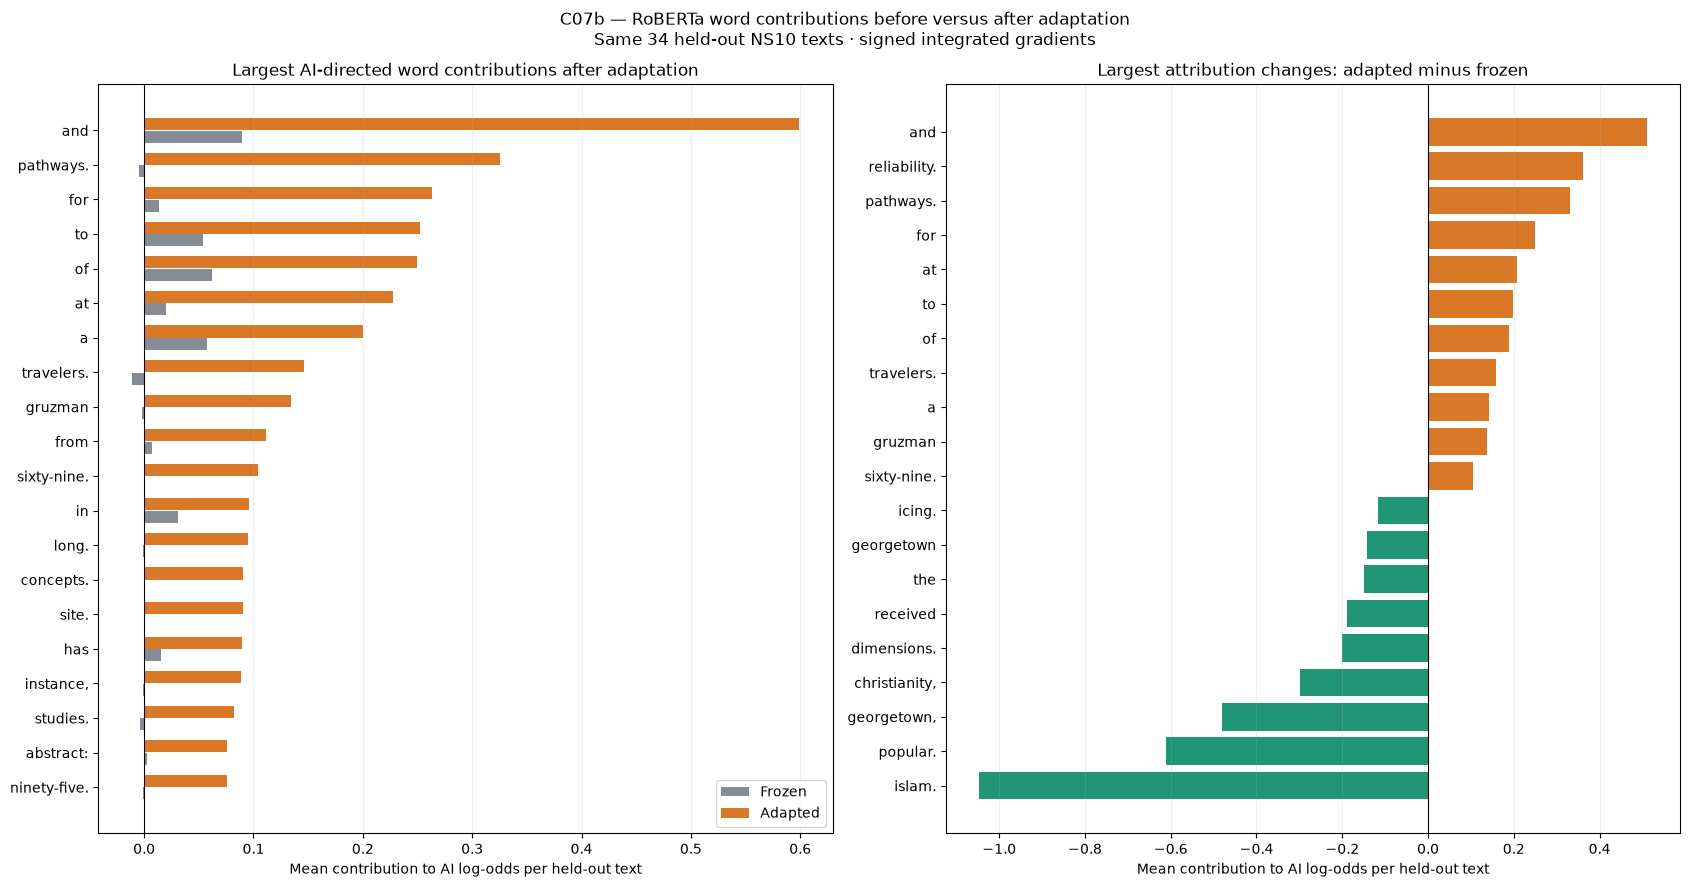

arm,Frozen,Adapted,Delta,cases_present
word,,,,
and,0.0893,0.5990,0.5097,34
reliability.,-0.4200,-0.0597,0.3603,1
pathways.,-0.0049,0.3252,0.3301,1
for,0.0132,0.2630,0.2498,31
at,0.0199,0.2274,0.2076,25
to,0.0539,0.2522,0.1983,34
of,0.0616,0.2499,0.1883,33
travelers.,-0.0113,0.1465,0.1578,1
a,0.0579,0.1998,0.1419,34


Saved: ../results/causal/C07b_RoBERTa_RAID_OG_NS10_v1/adaptation20_34_seed20260923/word_attributions
Baseline + word contributions ≈ AI log-odds. Attributions depend on the chosen embedding baseline; word rankings alone do not establish the causal reason for recovery.


In [10]:
# C07b: word contributions BEFORE versus AFTER adaptation
import re
import gc
from collections import defaultdict

ATTR = AD / "word_attributions"
ATTR.mkdir(exist_ok=True)
IG_POINTS = 32
TOP_N = 20

split = json.loads((AD / "split.json").read_text())
texts = ns.loc[
    ns.case_id.isin(split["test_cases"])
].sort_values("case_id").copy()
assert len(texts) == 34
assert tok.is_fast, "Offset mapping requires the existing fast tokenizer."

# Free previously loaded detectors.
for name in ("model", "trainer", "adapt_model", "adapt_trainer"):
    globals().pop(name, None)
gc.collect()
torch.cuda.empty_cache()

# Gauss–Legendre integration over the embedding interpolation path.
nodes, weights = np.polynomial.legendre.leggauss(IG_POINTS)
alphas, integration_weights = (nodes + 1) / 2, weights / 2
records = []

for arm, checkpoint in [("Frozen", BEST), ("Adapted", AD_BEST)]:
    files = sorted(checkpoint.glob("*.safetensors")) or sorted(
        checkpoint.glob("pytorch_model*.bin")
    )
    assert files
    checkpoint_hash = text_sha(json.dumps(
        {p.name: file_sha(p) for p in files}, sort_keys=True
    ))
    spec = dict(
        checkpoint=checkpoint_hash,
        points=IG_POINTS,
        max_tokens=MAX_TOKENS,
        baseline="zero_content_word_embeddings_fixed_specials_positions_mask",
        target="AI_logit_minus_Human_logit",
        precision="float32",
        transformers=importlib.metadata.version("transformers"),
        torch=torch.__version__,
    )
    spec_hash = text_sha(json.dumps(spec, sort_keys=True))

    def attribution_path(row):
        return ATTR / (
            text_sha(spec_hash + row.case_id + text_sha(row.text)) + ".json"
        )

    pending = [
        row for row in texts.itertuples(index=False)
        if not attribution_path(row).exists()
    ]
    detector = None
    try:
        if pending:
            detector = AutoModelForSequenceClassification.from_pretrained(
                checkpoint,
                torch_dtype=torch.float32,
                attn_implementation="eager",
            ).to("cuda").eval()
            detector.gradient_checkpointing_disable()
            detector.requires_grad_(False)
            embedding_layer = detector.get_input_embeddings()

        for row in tqdm(pending, desc=f"{arm}: integrated gradients"):
            encoded = tok(
                row.text,
                return_tensors="pt",
                truncation=True,
                max_length=MAX_TOKENS,
                return_offsets_mapping=True,
                return_special_tokens_mask=True,
            )
            offsets = encoded.pop("offset_mapping")[0].tolist()
            special = encoded.pop("special_tokens_mask").to("cuda").bool()
            encoded = encoded.to("cuda")

            with torch.no_grad():
                actual = embedding_layer(encoded.input_ids).detach()
            baseline = actual.clone()
            baseline[~special] = 0
            difference = actual - baseline

            # Hook only word embeddings: retain actual IDs, positions,
            # attention mask and special-token embeddings throughout.
            def margin_at(embeddings, with_gradient=False):
                handle = embedding_layer.register_forward_hook(
                    lambda module, inputs, output: embeddings
                )
                try:
                    with torch.set_grad_enabled(with_gradient):
                        logits = detector(**encoded).logits
                        return logits[0, 1] - logits[0, 0]
                finally:
                    handle.remove()

            gradient_integral = torch.zeros_like(actual)
            for alpha, weight in zip(alphas, integration_weights):
                point = (
                    baseline + float(alpha) * difference
                ).detach().requires_grad_(True)
                margin = margin_at(point, with_gradient=True)
                gradient = torch.autograd.grad(margin, point)[0]
                gradient_integral.add_(gradient.detach(), alpha=float(weight))
                del point, margin, gradient

            token_contributions = (
                difference * gradient_integral
            ).sum(-1)[0].detach().cpu().numpy()
            actual_margin = float(margin_at(actual).cpu())
            baseline_margin = float(margin_at(baseline).cpu())
            residual = (
                actual_margin - baseline_margin - token_contributions.sum()
            )

            # Merge subword contributions into whitespace-delimited words.
            # Distribute boundary-crossing pieces by character overlap.
            spans = list(re.finditer(r"\S+", row.text))
            word_values = defaultdict(float)
            for (start, end), value in zip(offsets, token_contributions):
                if end <= start:
                    continue
                overlaps = [
                    (m, max(0, min(end, m.end()) - max(start, m.start())))
                    for m in spans
                    if m.start() < end and m.end() > start
                ]
                total = sum(count for _, count in overlaps)
                if total:
                    for match, count in overlaps:
                        word_values[match.group().casefold()] += (
                            float(value) * count / total
                        )
                else:
                    word_values["<whitespace>"] += float(value)

            record = dict(
                arm=arm,
                case_id=row.case_id,
                text_sha=text_sha(row.text),
                specification=spec,
                AI_log_odds=actual_margin,
                baseline_log_odds=baseline_margin,
                contribution_sum=float(token_contributions.sum()),
                completeness_residual=float(residual),
                words=dict(word_values),
            )
            save_json(record, attribution_path(row))
            del actual, baseline, difference, gradient_integral, encoded

        for row in texts.itertuples(index=False):
            record = json.loads(attribution_path(row).read_text())
            assert record["specification"] == spec
            assert record["text_sha"] == text_sha(row.text)
            records.append(record)
    finally:
        del detector
        gc.collect()
        torch.cuda.empty_cache()

# Numerical audit: contributions should sum to actual minus baseline log-odds.
audit = pd.DataFrame([
    {k: v for k, v in r.items() if k not in ("words", "specification")}
    for r in records
])
audit["abs_residual"] = audit.completeness_residual.abs()
audit["tolerance"] = (
    0.05 + 0.05 * (audit.AI_log_odds - audit.baseline_log_odds).abs()
)
audit["integration_ok"] = audit.abs_residual.le(audit.tolerance)
save_csv(audit, ATTR / "attribution_audit.csv")
display(audit.groupby("arm").agg(
    mean_AI_log_odds=("AI_log_odds", "mean"),
    mean_baseline=("baseline_log_odds", "mean"),
    mean_word_sum=("contribution_sum", "mean"),
    max_abs_residual=("abs_residual", "max"),
    passing=("integration_ok", "sum"),
))
if not audit.integration_ok.all():
    print(
        "Some integrations have large residuals. Treat rankings as provisional; "
        "increase IG_POINTS to 64 or 128 and rerun. Existing results are retained."
    )

# Sum repeated occurrences within each case, then average over ALL 34 cases.
# Absent words contribute zero. These are frequency-weighted cohort effects.
rows = [
    dict(arm=r["arm"], case_id=r["case_id"], word=word, contribution=value)
    for r in records
    for word, value in r["words"].items()
]
long = pd.DataFrame(rows)
means = (
    long.groupby(["word", "arm"]).contribution.sum()
    .unstack("arm", fill_value=0)
    .reindex(columns=["Frozen", "Adapted"], fill_value=0)
    / len(texts)
)
means["Delta"] = means.Adapted - means.Frozen
means["cases_present"] = long.groupby("word").case_id.nunique()
save_csv(means.reset_index(), ATTR / "mean_word_contributions.csv")

# Panel 1: strongest AI-directed words after adaptation.
# Panel 2: largest changes in either direction.
top_ai = means.nlargest(TOP_N, "Adapted").sort_values("Adapted")
top_change = means.loc[
    means.Delta.abs().nlargest(TOP_N).index
].sort_values("Delta")

fig, axes = plt.subplots(1, 2, figsize=(17, 9))
y = np.arange(len(top_ai))
axes[0].barh(y - 0.18, top_ai.Frozen, height=0.35,
             color="#858C96", label="Frozen")
axes[0].barh(y + 0.18, top_ai.Adapted, height=0.35,
             color="#D97928", label="Adapted")
axes[0].set_yticks(y, top_ai.index)
axes[0].set_title("Largest AI-directed word contributions after adaptation")
axes[0].legend()

axes[1].barh(
    top_change.index,
    top_change.Delta,
    color=np.where(top_change.Delta >= 0, "#D97928", "#209675"),
)
axes[1].set_title("Largest attribution changes: adapted minus frozen")
for ax in axes:
    ax.axvline(0, color="black", lw=0.8)
    ax.set_xlabel("Mean contribution to AI log-odds per held-out text")
    ax.grid(axis="x", alpha=0.2)
fig.suptitle(
    "C07b — RoBERTa word contributions before versus after adaptation\n"
    "Same 34 held-out NS10 texts · signed integrated gradients"
)
fig.tight_layout()
for extension in ["png", "pdf"]:
    fig.savefig(
        ATTR / f"C07b_word_contributions.{extension}",
        dpi=300, bbox_inches="tight",
    )
plt.show()
plt.close(fig)

display(means.sort_values("Delta", ascending=False).head(25).round(4))
print("Saved:", ATTR)
print(
    "Baseline + word contributions ≈ AI log-odds. "
    "Attributions depend on the chosen embedding baseline; "
    "word rankings alone do not establish the causal reason for recovery."
)

Frozen 1/68 | NS10 gate_0001 | excess=+0.151
Frozen 2/68 | Human gate_0001 | excess=-0.002
Frozen 3/68 | NS10 gate_0015 | excess=+0.429
Frozen 4/68 | Human gate_0015 | excess=+0.054
Frozen 5/68 | NS10 gate_0022 | excess=+0.094
Frozen 6/68 | Human gate_0022 | excess=+0.051
Frozen 7/68 | NS10 gate_0028 | excess=+1.723
Frozen 8/68 | Human gate_0028 | excess=+0.040
Frozen 9/68 | NS10 gate_0046 | excess=+1.002
Frozen 10/68 | Human gate_0046 | excess=+0.104
Frozen 11/68 | NS10 gate_0090 | excess=-0.099
Frozen 12/68 | Human gate_0090 | excess=+0.033
Frozen 13/68 | NS10 gate_0092 | excess=+0.182
Frozen 14/68 | Human gate_0092 | excess=+0.036
Frozen 15/68 | NS10 gate_0035 | excess=-0.056
Frozen 16/68 | Human gate_0035 | excess=+0.011
Frozen 17/68 | NS10 gate_0047 | excess=+0.020
Frozen 18/68 | Human gate_0047 | excess=-0.011
Frozen 19/68 | NS10 gate_0065 | excess=+0.077
Frozen 20/68 | Human gate_0065 | excess=+0.025
Frozen 21/68 | NS10 gate_0070 | excess=+0.160
Frozen 22/68 | Human gate_0070 | 

,arm,group,metric,mean,ci_low,ci_high
0,Adapted,Human,function_drop,0.668,0.154,1.460
1,Adapted,Human,random_drop,0.629,0.114,1.429
2,Adapted,Human,excess_drop,0.038,0.013,0.066
3,Adapted,NS10,function_drop,7.513,6.100,8.891
4,Adapted,NS10,random_drop,7.184,5.877,8.419
5,Adapted,NS10,excess_drop,0.329,-0.393,1.092
6,Frozen,Human,function_drop,0.319,0.106,0.639
7,Frozen,Human,random_drop,0.277,0.059,0.606
8,Frozen,Human,excess_drop,0.041,0.024,0.061
9,Frozen,NS10,function_drop,1.733,1.067,2.514


,comparison,mean,ci_low,ci_high
0,Adaptation shift: NS10,0.180,-0.523,0.924
1,Adaptation shift: Human,-0.003,-0.021,0.016
2,NS10 shift minus Human shift,0.183,-0.524,0.932


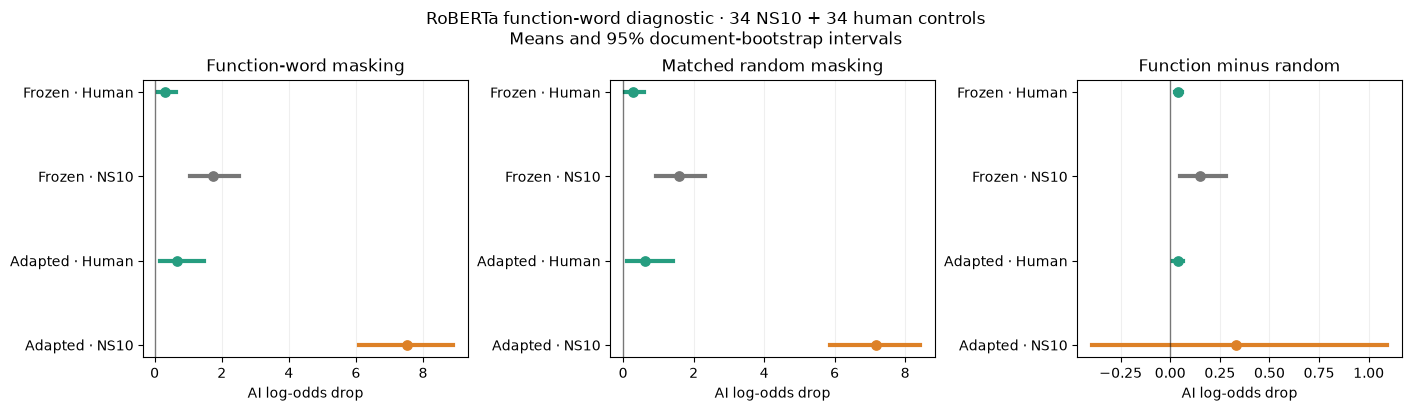

Saved: ../results/causal/C07b_RoBERTa_RAID_OG_NS10_v1/adaptation20_34_seed20260923/function_word_masking_v1
Masking is a contextual sensitivity diagnostic. It does not establish a word-count shortcut or explain adaptation causally.


In [11]:
# Diagnostic only: saved NS10 texts and detector weights remain unchanged.
import re, gc, json, hashlib
from pathlib import Path
import numpy as np
import pandas as pd
import torch
import matplotlib.pyplot as plt
from transformers import AutoModelForSequenceClassification
from IPython.display import display

AD = OUT / "adaptation20_34_seed20260923"
DIAG = AD / "function_word_masking_v1"
DIAG.mkdir(parents=True, exist_ok=True)

WORDS = {"and", "for", "to", "of", "a", "at", "in", "from", "the"}
RANDOM_REPEATS = 5
SEED_DIAG = 20260924
LIMIT = 512

split = json.loads((AD / "split.json").read_text())
held = ns.loc[
    ns.case_id.astype(str).isin(map(str, split["test_cases"]))
].copy().sort_values("case_id")
assert len(held) == 34 and held.case_id.is_unique

# Human controls: original RAID test split only, same domain counts.
rng = np.random.default_rng(SEED_DIAG)
human_pool = raid.loc[
    raid.label.eq(0) & raid.split.eq("test")
].drop_duplicates("source_id")

records = []
for domain, group in held.groupby("domain", sort=True):
    candidates = human_pool.loc[
        human_pool.domain.eq(domain)
    ].sort_values("source_id")
    assert len(candidates) >= len(group), f"Not enough humans: {domain}"
    chosen = candidates.iloc[
        rng.choice(len(candidates), len(group), replace=False)
    ]
    for ai, human in zip(group.itertuples(), chosen.itertuples()):
        for kind, row in [("NS10", ai), ("Human", human)]:
            records.append(dict(
                pair_id=str(ai.case_id), group=kind,
                source_id=str(row.source_id), domain=domain,
                text=str(row.text),
            ))
diagnostic_docs = pd.DataFrame(records)

checkpoints = {
    "Frozen": OUT / "best_model",
    "Adapted": AD / "best_model",
}
checkpoint_hashes = {}
for arm, path in checkpoints.items():
    weights = sorted(path.glob("*.safetensors")) or sorted(path.glob("*.bin"))
    assert weights, f"No weights found: {path}"
    checkpoint_hashes[arm] = {p.name: file_sha(p) for p in weights}

protocol = dict(
    version=1, words=sorted(WORDS), random_repeats=RANDOM_REPEATS,
    seed=SEED_DIAG, max_tokens=LIMIT, precision="float32",
    target="AI_logit_minus_human_logit",
    random_control="equal_subword_count_from_non_function_content_tokens",
    checkpoints=checkpoint_hashes,
    documents=[
        dict(pair_id=r.pair_id, group=r.group, source_id=r.source_id,
             text_sha=text_sha(r.text))
        for r in diagnostic_docs.itertuples()
    ],
)
freeze(protocol, DIAG / "protocol.json")
protocol_hash = text_sha(json.dumps(protocol, sort_keys=True))

# Release models left by training or attribution cells.
for name in ("model", "trainer", "adapt_model", "adapt_trainer",
             "ig_model", "diag_model"):
    globals().pop(name, None)
gc.collect()
torch.cuda.empty_cache()

assert tok.is_fast and tok.mask_token_id is not None
all_results = []

for arm, checkpoint in checkpoints.items():
    pending = []
    for row in diagnostic_docs.itertuples():
        key = text_sha(
            f"{protocol_hash}|{arm}|{row.group}|{row.pair_id}"
        )
        path = DIAG / f"{key}.json"
        if path.exists():
            all_results.append(json.loads(path.read_text()))
        else:
            pending.append((row, path))

    if not pending:
        print(f"{arm}: all cached", flush=True)
        continue

    diag_model = AutoModelForSequenceClassification.from_pretrained(
        checkpoint, torch_dtype=torch.float32,
        attn_implementation="eager",
    ).to("cuda").eval()
    diag_model.requires_grad_(False)

    @torch.inference_mode()
    def ai_margin(ids, attention):
        logits = diag_model(
            input_ids=ids, attention_mask=attention
        ).logits.float()[0]
        return float((logits[1] - logits[0]).cpu())

    for number, (row, path) in enumerate(pending, 1):
        enc = tok(
            row.text, truncation=True, max_length=LIMIT,
            return_offsets_mapping=True,
            return_special_tokens_mask=True,
            return_tensors="pt",
        )
        offsets = enc.pop("offset_mapping")[0].tolist()
        special = enc.pop("special_tokens_mask")[0].bool().numpy()
        ids = enc["input_ids"].to("cuda")
        attention = enc["attention_mask"].to("cuda")

        spans = [
            m.span() for m in re.finditer(r"\b[A-Za-z]+\b", row.text)
            if m.group().lower() in WORDS
        ]
        content = [
            i for i, (start, end) in enumerate(offsets)
            if not special[i] and end > start
        ]
        selected = [
            i for i in content
            if any(offsets[i][0] < end and offsets[i][1] > start
                   for start, end in spans)
        ]
        selected_set = set(selected)
        alternatives = [i for i in content if i not in selected_set]
        assert len(alternatives) >= len(selected), (
            "Insufficient non-function tokens for matched masks."
        )

        def masked_margin(positions):
            modified = ids.clone()
            modified[0, positions] = tok.mask_token_id
            return ai_margin(modified, attention)

        original = ai_margin(ids, attention)
        function_masked = masked_margin(selected)

        # Same random masks for Frozen and Adapted.
        local_seed = int(text_sha(
            f"{SEED_DIAG}|{row.group}|{row.pair_id}|{row.text}"
        )[:16], 16)
        local_rng = np.random.default_rng(local_seed)
        random_margins = [
            masked_margin(local_rng.choice(
                alternatives, len(selected), replace=False
            ).tolist())
            for _ in range(RANDOM_REPEATS)
        ]
        function_drop = original - function_masked
        random_drop = original - float(np.mean(random_margins))

        result = dict(
            arm=arm, group=row.group, pair_id=row.pair_id,
            domain=row.domain, source_id=row.source_id,
            content_tokens=len(content), masked_tokens=len(selected),
            original_log_odds=original,
            function_masked_log_odds=function_masked,
            random_masked_log_odds=random_margins,
            function_drop=function_drop, random_drop=random_drop,
            excess_drop=function_drop - random_drop,
        )
        save_json(result, path)
        all_results.append(result)
        print(
            f"{arm} {number}/{len(pending)} | "
            f"{row.group} {row.pair_id} | "
            f"excess={result['excess_drop']:+.3f}",
            flush=True,
        )

    del diag_model
    gc.collect()
    torch.cuda.empty_cache()

mask_results = pd.DataFrame(all_results)
save_csv(mask_results, DIAG / "masking_results.csv")

# Equal document weighting; bootstrap documents, not individual tokens.
def estimate(values):
    values = np.asarray(values, dtype=float)
    r = np.random.default_rng(SEED_DIAG)
    boot = values[r.integers(0, len(values), (10000, len(values)))].mean(1)
    return dict(
        mean=values.mean(),
        ci_low=np.quantile(boot, .025),
        ci_high=np.quantile(boot, .975),
    )

summary = []
for (arm, group), frame in mask_results.groupby(["arm", "group"]):
    for metric in ["function_drop", "random_drop", "excess_drop"]:
        summary.append(dict(
            arm=arm, group=group, metric=metric,
            **estimate(frame[metric]),
        ))
mask_summary = pd.DataFrame(summary)
display(mask_summary.round(3))
save_csv(mask_summary, DIAG / "masking_summary.csv")

# Did adaptation increase sensitivity specifically on NS10?
wide = mask_results.pivot(
    index=["pair_id", "group"], columns="arm", values="excess_drop"
)
shift = (wide["Adapted"] - wide["Frozen"]).unstack("group")
contrasts = pd.DataFrame([
    dict(comparison="Adaptation shift: NS10", **estimate(shift["NS10"])),
    dict(comparison="Adaptation shift: Human", **estimate(shift["Human"])),
    dict(
        comparison="NS10 shift minus Human shift",
        **estimate(shift["NS10"] - shift["Human"]),
    ),
])
display(contrasts.round(3))
save_csv(contrasts, DIAG / "adaptation_contrasts.csv")

fig, axes = plt.subplots(1, 3, figsize=(14, 4), constrained_layout=True)
order = [
    ("Frozen", "Human"), ("Frozen", "NS10"),
    ("Adapted", "Human"), ("Adapted", "NS10"),
]
colors = ["#269d80", "#777777", "#269d80", "#dd8127"]
for ax, metric, title in zip(
    axes,
    ["function_drop", "random_drop", "excess_drop"],
    ["Function-word masking", "Matched random masking",
     "Function minus random"],
):
    for y, ((arm, group), color) in enumerate(zip(order, colors)):
        r = mask_summary.loc[
            mask_summary.arm.eq(arm)
            & mask_summary.group.eq(group)
            & mask_summary.metric.eq(metric)
        ].iloc[0]
        ax.plot([r.ci_low, r.ci_high], [y, y], color=color, lw=3)
        ax.scatter(r["mean"], y, color=color, s=45, zorder=3)
    ax.axvline(0, color="black", lw=1, alpha=.5)
    ax.set_yticks(range(4), [f"{a} · {g}" for a, g in order])
    ax.invert_yaxis()
    ax.set_title(title)
    ax.set_xlabel("AI log-odds drop")
    ax.grid(axis="x", alpha=.2)

fig.suptitle(
    "RoBERTa function-word diagnostic · 34 NS10 + 34 human controls\n"
    "Means and 95% document-bootstrap intervals"
)
fig.savefig(DIAG / "function_word_masking.png", dpi=180)
fig.savefig(DIAG / "function_word_masking.pdf")
plt.show()

print("Saved:", DIAG)
print(
    "Masking is a contextual sensitivity diagnostic. "
    "It does not establish a word-count shortcut or explain adaptation causally."
)

max_steps is given, it will override any value given in num_train_epochs


RAID-only continuation: 240 optimizer steps; resume=new run


Step,Training Loss,Validation Loss
25,0.025100,0.156373
50,0.102700,0.210436
75,0.172100,0.179961
100,0.083100,0.183808
125,0.002500,0.225549
150,0.086500,0.420304
175,0.052300,0.270210
200,0.074000,0.225160
225,0.046900,0.263908


Frozen: 25/287 scored
Frozen: 50/287 scored
Frozen: 75/287 scored
Frozen: 100/287 scored
Frozen: 125/287 scored
Frozen: 150/287 scored
Frozen: 175/287 scored
Frozen: 200/287 scored
Frozen: 225/287 scored
Frozen: 250/287 scored
Frozen: 275/287 scored
Frozen: 287/287 scored
RAID-only continuation: 25/287 scored
RAID-only continuation: 50/287 scored
RAID-only continuation: 75/287 scored
RAID-only continuation: 100/287 scored
RAID-only continuation: 125/287 scored
RAID-only continuation: 150/287 scored
RAID-only continuation: 175/287 scored
RAID-only continuation: 200/287 scored
RAID-only continuation: 225/287 scored
RAID-only continuation: 250/287 scored
RAID-only continuation: 275/287 scored
RAID-only continuation: 287/287 scored
Adapted (+20 NS10): 25/287 scored
Adapted (+20 NS10): 50/287 scored
Adapted (+20 NS10): 75/287 scored
Adapted (+20 NS10): 100/287 scored
Adapted (+20 NS10): 125/287 scored
Adapted (+20 NS10): 150/287 scored
Adapted (+20 NS10): 175/287 scored
Adapted (+20 NS10): 

,arm,cases,AUROC,mean_AI_score,median_AI_score
0,Frozen,34,0.729107,0.186319,0.027068
1,RAID-only continuation,34,0.770501,0.363160,0.016353
2,Adapted (+20 NS10),34,0.965662,0.876828,0.998412


,comparison,AUROC_delta,ci_low,ci_high,increased,decreased
0,RAID-only continuation minus Frozen,0.041394,0.013223,0.076105,19,9
1,Adapted (+20 NS10) minus Frozen,0.236555,0.151681,0.328964,33,0
2,Adapted (+20 NS10) minus RAID-only continuation,0.195161,0.124606,0.273950,33,0


,arm,threshold,calibration_FPR,test_FPR,TPR,target_FPR
3,Frozen,0.537770,0.004902,0.023343,0.147059,0.01
5,Frozen,0.042088,0.044771,0.079715,0.441176,0.05
6,Frozen,0.024988,0.099346,0.105257,0.529412,0.10
13,RAID-only continuation,0.974629,0.005882,0.039683,0.235294,0.01
15,RAID-only continuation,0.050705,0.044652,0.074813,0.470588,0.05
16,RAID-only continuation,0.024054,0.094534,0.097904,0.470588,0.10
23,Adapted (+20 NS10),0.973645,0.005882,0.036415,0.764706,0.01
25,Adapted (+20 NS10),0.072637,0.046732,0.051937,0.911765,0.05
26,Adapted (+20 NS10),0.011687,0.099486,0.090715,0.941176,0.10


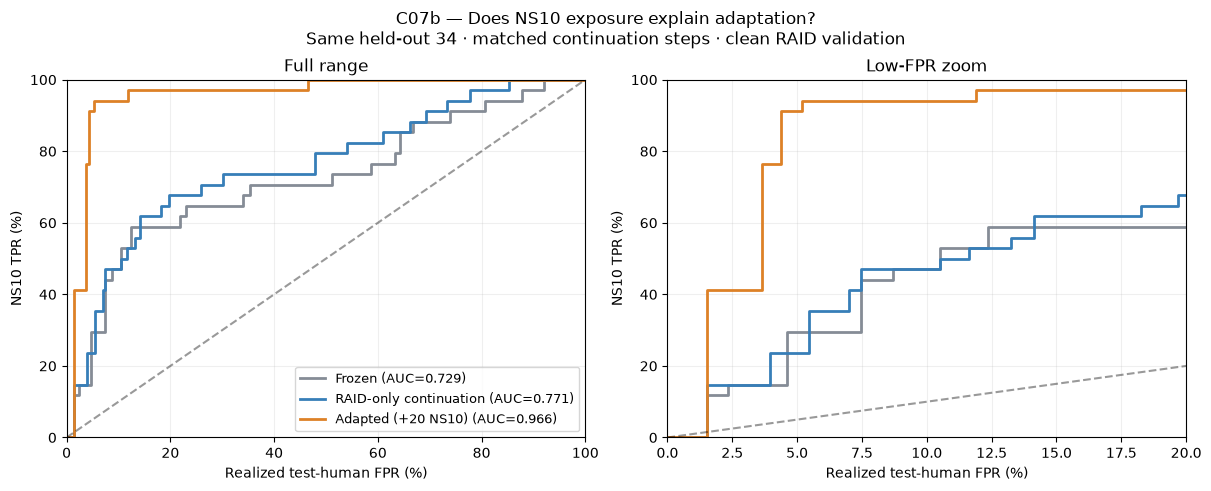

Saved: ../results/causal/C07b_RoBERTa_RAID_OG_NS10_v1/adaptation20_34_seed20260923/raid_only_control
Key comparison: Adapted (+20 NS10) minus RAID-only continuation. Intervals resample held-out cases with fixed human references and models; they exclude training-seed uncertainty.


In [12]:
import copy, gc, json
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import torch
from transformers import (
    AutoModelForSequenceClassification, Trainer,
    DataCollatorWithPadding, set_seed,
)
from transformers.trainer_utils import get_last_checkpoint

AD = OUT / "adaptation20_34_seed20260923"
CTRL = AD / "raid_only_control"
CTRL.mkdir(parents=True, exist_ok=True)
CBEST = CTRL / "best_model"
CDONE = CTRL / "training_complete.json"

split = json.loads((AD / "split.json").read_text())
test_ids = list(map(str, split["test_cases"]))
adapt_ids = list(map(str, split["adaptation_cases"]))
assert len(test_ids) == 34 and not set(test_ids) & set(adapt_ids)

# Read the actual adaptation settings instead of reconstructing them.
args_file = AD / "best_model" / "training_args.bin"
assert args_file.exists(), f"Missing saved adaptation arguments: {args_file}"
adapt_args = torch.load(
    args_file, map_location="cpu", weights_only=False
)

# Prefer the completion manifest's actual number of optimizer updates.
adapt_done_path = AD / "training_complete.json"
assert adapt_done_path.exists(), (
    "Adaptation completion manifest is missing; finish adaptation first."
)
adapt_done = json.loads(adapt_done_path.read_text())
assert "global_step" in adapt_done, (
    "Adaptation manifest has no global_step. Need its final optimizer-step "
    "count, not the selected best checkpoint's step."
)
matched_steps = int(adapt_done["global_step"])
assert matched_steps > 0
assert str(adapt_args.eval_strategy).lower().endswith("steps")
assert str(adapt_args.save_strategy).lower().endswith("steps")

# Preserve all optimizer, batch, precision, validation and selection settings.
control_args = copy.deepcopy(adapt_args)
control_args.output_dir = str(CTRL / "training")
control_args.logging_dir = str(CTRL / "logs")
control_args.max_steps = matched_steps
control_args.overwrite_output_dir = False
control_args.report_to = []
control_args.push_to_hub = False

def weights_digest(path):
    files = sorted(Path(path).glob("*.safetensors"))
    if not files:
        files = sorted(Path(path).glob("pytorch_model*.bin"))
    assert files, f"No model weights: {path}"
    return text_sha(json.dumps(
        {p.name: file_sha(p) for p in files}, sort_keys=True
    ))

control_contract = dict(
    version=1,
    start_checkpoint=weights_digest(OUT / "best_model"),
    adaptation_checkpoint=weights_digest(AD / "best_model"),
    adaptation_arguments_sha=file_sha(args_file),
    optimizer_steps=matched_steps,
    train_rows=len(tr),
    train_sha=text_sha(
        tr[["source_id", "text", "label"]].to_json(orient="records")
    ),
    validation_sha=text_sha(
        va[["source_id", "text", "label"]].to_json(orient="records")
    ),
    held_out_cases=test_ids,
    settings=control_args.to_dict(),
)
freeze(control_contract, CTRL / "protocol.json")
control_signature = text_sha(
    json.dumps(control_contract, sort_keys=True)
)

# Free models left by previous cells.
for name in (
    "model", "trainer", "adapt_model", "adapt_trainer",
    "ig_model", "diag_model", "control_model", "control_trainer",
):
    globals().pop(name, None)
gc.collect()
torch.cuda.empty_cache()

if CDONE.exists():
    assert json.loads(CDONE.read_text())["contract"] == control_signature
    assert (CBEST / "config.json").exists()
    print("Using saved RAID-only control.", flush=True)
else:
    set_seed(control_args.seed)
    control_model = AutoModelForSequenceClassification.from_pretrained(
        OUT / "best_model", attn_implementation="eager",
        torch_dtype=torch.float32,
    )
    control_trainer = Trainer(
        model=control_model,
        args=control_args,
        train_dataset=TextDataset(tr),
        eval_dataset=TextDataset(va),
        data_collator=DataCollatorWithPadding(tok, pad_to_multiple_of=8),
        tokenizer=tok,
    )
    train_dir = Path(control_args.output_dir)
    train_dir.mkdir(parents=True, exist_ok=True)
    last = get_last_checkpoint(str(train_dir))
    print(
        f"RAID-only continuation: {matched_steps} optimizer steps; "
        f"resume={last or 'new run'}",
        flush=True,
    )
    control_trainer.train(resume_from_checkpoint=last)
    assert control_trainer.state.global_step == matched_steps

    # Trainer has restored the checkpoint selected by clean RAID validation.
    control_trainer.save_model(str(CBEST))
    tok.save_pretrained(CBEST)
    save_json(control_trainer.state.log_history, CTRL / "training_log.json")
    save_json(dict(
        contract=control_signature,
        global_step=control_trainer.state.global_step,
        best_checkpoint=control_trainer.state.best_model_checkpoint,
        best_validation_loss=float(control_trainer.state.best_metric),
    ), CDONE)
    del control_trainer, control_model
    gc.collect()
    torch.cuda.empty_cache()

# Identical evaluation documents for all three detectors.
held = ns.loc[ns.case_id.astype(str).isin(test_ids)].copy()
held["case_id"] = held.case_id.astype(str)
held = held.sort_values("case_id")
assert len(held) == 34 and held.case_id.is_unique
mix = held.domain.value_counts(normalize=True)

human_docs = raid.loc[
    raid.label.eq(0)
    & raid.split.isin(["validation", "test"])
    & raid.domain.isin(mix.index)
].copy()
human_docs["stage"] = "Human"
human_docs["case_id"] = ""

ai_docs = held.assign(stage="NS10", split="test")
evaluation = pd.concat([
    human_docs[["case_id", "source_id", "domain", "split", "stage", "text"]],
    ai_docs[["case_id", "source_id", "domain", "split", "stage", "text"]],
], ignore_index=True)
evaluation["text_sha"] = evaluation.text.astype(str).map(text_sha)
assert not evaluation.loc[
    evaluation.stage.eq("NS10"), "case_id"
].isin(adapt_ids).any()

checkpoints = {
    "Frozen": OUT / "best_model",
    "RAID-only continuation": CBEST,
    "Adapted (+20 NS10)": AD / "best_model",
}
score_dir = CTRL / "scores"
score_dir.mkdir(exist_ok=True)
frames = []

# Re-score all arms consistently; each text is cached.
for arm, checkpoint in checkpoints.items():
    digest = weights_digest(checkpoint)
    scoring_contract = dict(
        weights=digest, max_tokens=MAX_TOKENS,
        precision="fp32_parameters_bf16_autocast",
        torch=torch.__version__,
        tokenizer_sha=text_sha(tok.backend_tokenizer.to_str()),
    )
    score_sig = text_sha(json.dumps(scoring_contract, sort_keys=True))
    unique = evaluation[["text_sha", "text"]].drop_duplicates("text_sha")

    def cache_path(sha):
        return score_dir / (text_sha(score_sig + sha) + ".json")

    pending = [
        r for r in unique.itertuples()
        if not cache_path(r.text_sha).exists()
    ]
    if pending:
        eval_model = AutoModelForSequenceClassification.from_pretrained(
            checkpoint, attn_implementation="eager",
            torch_dtype=torch.float32,
        ).to("cuda").eval()
        for i, r in enumerate(pending, 1):
            enc = tok(
                r.text, return_tensors="pt",
                truncation=True, max_length=MAX_TOKENS,
            ).to("cuda")
            with torch.inference_mode(), torch.autocast(
                "cuda", dtype=torch.bfloat16
            ):
                logits = eval_model(**enc).logits
            score = float(logits.float().softmax(-1)[0, 1].cpu())
            save_json(
                dict(AI_score=score, text_sha=r.text_sha,
                     score_contract=score_sig),
                cache_path(r.text_sha),
            )
            if i % 25 == 0 or i == len(pending):
                print(f"{arm}: {i}/{len(pending)} scored", flush=True)
        del eval_model
        gc.collect()
        torch.cuda.empty_cache()

    frame = evaluation.drop(columns="text").copy()
    frame["arm"] = arm
    frame["AI_score"] = [
        json.loads(cache_path(sha).read_text())["AI_score"]
        for sha in frame.text_sha
    ]
    frames.append(frame)

control_scores = pd.concat(frames, ignore_index=True)
save_csv(control_scores, CTRL / "all_scores.csv")

# Genre-weighted human references; equal weighting of the 34 NS10 cases.
summaries, stairs, operating, contributions = [], [], [], {}
for arm, frame in control_scores.groupby("arm", sort=False):
    ai = frame.loc[frame.stage.eq("NS10")].set_index("case_id")
    ai = ai.loc[held.case_id]
    ai_scores = ai.AI_score.to_numpy()

    def human_reference(which_split):
        h = frame.loc[
            frame.stage.eq("Human") & frame.split.eq(which_split)
        ].copy()
        counts = h.domain.value_counts()
        assert set(mix.index) <= set(counts.index)
        h["weight"] = [mix[d] / counts[d] for d in h.domain]
        assert np.isclose(h.weight.sum(), 1)
        return h

    cal = human_reference("validation")
    human = human_reference("test")
    hs = human.AI_score.to_numpy()
    hw = human.weight.to_numpy()
    a = ai_scores[:, None]
    per_case_auc = (((a > hs) + .5 * (a == hs)) * hw).sum(axis=1)
    contributions[arm] = per_case_auc

    summaries.append(dict(
        arm=arm, cases=len(ai),
        AUROC=per_case_auc.mean(),
        mean_AI_score=ai_scores.mean(),
        median_AI_score=np.median(ai_scores),
    ))
    cuts = np.r_[np.inf, np.unique(cal.AI_score)[::-1], -np.inf]
    st = pd.DataFrame(dict(
        arm=arm, threshold=cuts,
        calibration_FPR=[
            cal.loc[cal.AI_score > c, "weight"].sum() for c in cuts
        ],
        test_FPR=[hw[hs > c].sum() for c in cuts],
        TPR=[(ai_scores > c).mean() for c in cuts],
    ))
    stairs.append(st)
    for target in [0, .001, .005, .01, .02, .05, .1, .2, .5, 1]:
        row = st.loc[st.calibration_FPR <= target + 1e-12].iloc[-1]
        operating.append({**row.to_dict(), "target_FPR": target})

control_summary = pd.DataFrame(summaries)
control_staircase = pd.concat(stairs, ignore_index=True)
control_operating = pd.DataFrame(operating)

rng = np.random.default_rng(20260923)
ix = rng.integers(0, 34, size=(10000, 34))
comparisons = []
for left, right in [
    ("Frozen", "RAID-only continuation"),
    ("Frozen", "Adapted (+20 NS10)"),
    ("RAID-only continuation", "Adapted (+20 NS10)"),
]:
    delta = contributions[right] - contributions[left]
    lo, hi = np.quantile(delta[ix].mean(axis=1), [.025, .975])
    comparisons.append(dict(
        comparison=f"{right} minus {left}",
        AUROC_delta=delta.mean(), ci_low=lo, ci_high=hi,
        increased=int((delta > 0).sum()),
        decreased=int((delta < 0).sum()),
    ))
control_comparisons = pd.DataFrame(comparisons)

for name, frame in [
    ("summary", control_summary),
    ("staircase", control_staircase),
    ("operating_points", control_operating),
    ("paired_AUROC_changes", control_comparisons),
]:
    save_csv(frame, CTRL / f"{name}.csv")

display(control_summary.round(6))
display(control_comparisons.round(6))
display(control_operating.loc[
    control_operating.target_FPR.isin([.01, .05, .1])
].round(6))

colors = {
    "Frozen": "#858C96",
    "RAID-only continuation": "#377EB8",
    "Adapted (+20 NS10)": "#DD8127",
}
fig, axes = plt.subplots(1, 2, figsize=(12, 4.8), constrained_layout=True)
for ax, xmax in zip(axes, [100, 20]):
    for arm, color in colors.items():
        st = control_staircase.loc[control_staircase.arm.eq(arm)]
        auc_value = control_summary.set_index("arm").loc[arm, "AUROC"]
        ax.step(
            100 * st.test_FPR, 100 * st.TPR, where="post",
            color=color, lw=2, label=f"{arm} (AUC={auc_value:.3f})",
        )
    ax.plot([0, xmax], [0, xmax], "--", color="black", alpha=.4)
    ax.set(
        xlim=(0, xmax), ylim=(0, 100),
        xlabel="Realized test-human FPR (%)", ylabel="NS10 TPR (%)",
        title="Full range" if xmax == 100 else "Low-FPR zoom",
    )
    ax.grid(alpha=.2)
axes[0].legend(fontsize=9)
fig.suptitle(
    "C07b — Does NS10 exposure explain adaptation?\n"
    "Same held-out 34 · matched continuation steps · clean RAID validation"
)
for ext in ("png", "pdf"):
    fig.savefig(CTRL / f"RAID_only_control_TPR.{ext}", dpi=200)
plt.show()

print("Saved:", CTRL)
print(
    "Key comparison: Adapted (+20 NS10) minus RAID-only continuation. "
    "Intervals resample held-out cases with fixed human references and models; "
    "they exclude training-seed uncertainty."
)

Frozen: 20/157
Frozen: 40/157
Frozen: 60/157
Frozen: 80/157
Frozen: 100/157
Frozen: 120/157
Frozen: 140/157
Frozen: 157/157
RAID-only continuation: 20/157
RAID-only continuation: 40/157
RAID-only continuation: 60/157
RAID-only continuation: 80/157
RAID-only continuation: 100/157
RAID-only continuation: 120/157
RAID-only continuation: 140/157
RAID-only continuation: 157/157
Adapted (+20 NS10): 20/157
Adapted (+20 NS10): 40/157
Adapted (+20 NS10): 60/157
Adapted (+20 NS10): 80/157
Adapted (+20 NS10): 100/157
Adapted (+20 NS10): 120/157
Adapted (+20 NS10): 140/157
Adapted (+20 NS10): 157/157


cases  mean_AI_score  mean_AI_log_odds   AUROC  \
stage arm                                                                      
NEW   Adapted (+20 NS10)         34         0.9995            7.6847  0.9994   
      Frozen                     34         0.9982            6.3424  1.0000   
      RAID-only continuation     34         0.9992            7.1728  0.9993   
NS10  Adapted (+20 NS10)         34         0.8768            4.8691  0.9657   
      Frozen                     34         0.1863           -2.5756  0.7307   
      RAID-only continuation     34         0.3632           -1.4867  0.7743   
NS4   Adapted (+20 NS10)         34         0.8799            4.8797  0.9646   
      Frozen                     34         0.2309           -2.2326  0.7533   
      RAID-only continuation     34         0.4179           -1.0446  0.7885   
NS8   Adapted (+20 NS10)         34         0.8698            4.6305  0.9645   
      Frozen                     34         0.1880           -2.5654  0.7285   
      RAID-only continuation     34         0.3585           -1.5575  0.7684   
OG    Adapted (+20 NS10)         34         0.9713            7.1946  0.9951   
      Frozen                     34         0.9412            5.4238  0.9917   
      RAID-only continuation     34         0.9521            6.4016  0.9899   

                              truncated  
stage arm                                
NEW   Adapted (+20 NS10)             16  
      Frozen                         16  
      RAID-only continuation         16  
NS10  Adapted (+20 NS10)             16  
      Frozen                         16  
      RAID-only continuation         16  
NS4   Adapted (+20 NS10)             16  
      Frozen                         16  
      RAID-only continuation         16  
NS8   Adapted (+20 NS10)             16  
      Frozen                         16  
      RAID-only continuation         16  
OG    Adapted (+20 NS10)              0  
      Frozen                          0  
      RAID-only continuation          0

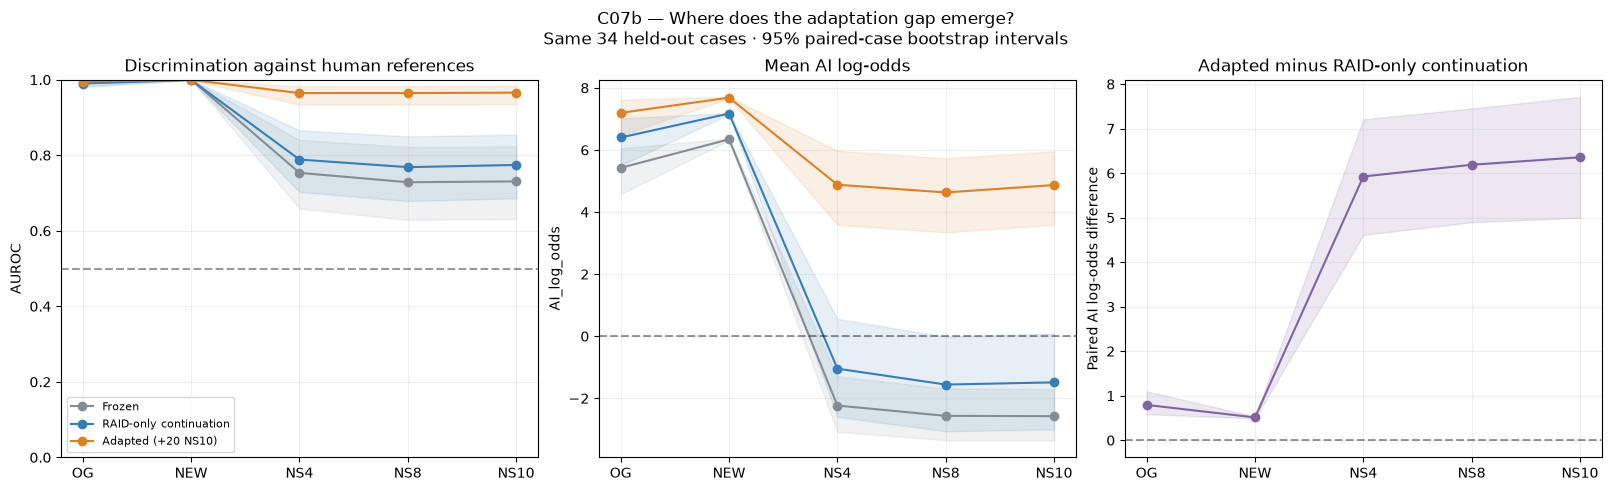

Changes in the adaptation gap between adjacent stages:


,metric,transition,mean,ci_low,ci_high
0,AUROC,OG → NEW,-0.0051,-0.0113,-0.0007
1,AUROC,NEW → NS4,0.1760,0.1107,0.2488
2,AUROC,NS4 → NS8,0.0201,0.0082,0.0371
3,AUROC,NS8 → NS10,-0.0047,-0.0134,0.0024
4,AI_log_odds,OG → NEW,-0.2811,-0.5847,-0.0779
5,AI_log_odds,NEW → NS4,5.4123,4.0994,6.6975
6,AI_log_odds,NS4 → NS8,0.2638,-0.0668,0.6639
7,AI_log_odds,NS8 → NS10,0.1678,-0.0432,0.4082


Saved: ../results/causal/C07b_RoBERTa_RAID_OG_NS10_v1/adaptation20_34_seed20260923/stage_localization_v1
Positive transition values mean the adaptation gap widened. These are exploratory stage associations, not identification of a specific learned feature. Check truncation counts alongside the plots.


In [13]:
import gc, json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import torch
from transformers import AutoModelForSequenceClassification

AD = OUT / "adaptation20_34_seed20260923"
CTRL = AD / "raid_only_control"
STAGE_OUT = AD / "stage_localization_v1"
STAGE_OUT.mkdir(parents=True, exist_ok=True)
(STAGE_OUT / "scores").mkdir(exist_ok=True)

split = json.loads((AD / "split.json").read_text())
ids = sorted(map(str, split["test_cases"]))
assert len(ids) == 34
assert not set(ids) & set(map(str, split["adaptation_cases"]))

C06 = ROOT / "results/causal/C06_NEW_step4_Ghostbuster_v1"
C06B = ROOT / "results/causal/C06b_NEW_steps5_10_v1"
stage_paths = {
    "NEW": C06 / "NEW_inputs_54.csv",
    "NS4": C06 / "NEW_step4_texts_54.csv",
    "NS8": C06B / "NS8_texts.csv",
    "NS10": C06B / "NS10_texts.csv",
}
stages = ["OG", "NEW", "NS4", "NS8", "NS10"]
reference = ns.copy()
reference["case_id"] = reference.case_id.astype(str)
reference = reference.set_index("case_id").loc[ids]

def align_stage(frame):
    frame = frame.copy()
    frame["case_id"] = frame.case_id.astype(str)
    assert frame.case_id.is_unique
    frame = frame.set_index("case_id").loc[ids]
    assert frame.source_id.astype(str).tolist() == reference.source_id.astype(str).tolist()
    assert frame.domain.tolist() == reference.domain.tolist()
    assert frame.text.notna().all() and frame.text.str.strip().ne("").all()
    if "text_sha" in frame:
        assert frame.text.map(text_sha).eq(frame.text_sha).all()
    return frame.reset_index()[["case_id", "source_id", "domain", "text"]]

original = reference.reset_index()[["case_id", "source_id", "domain"]]
original["text"] = original.source_id.map(raid.set_index("source_id").text)
parts = [align_stage(original).assign(stage="OG")]
for stage, path in stage_paths.items():
    assert path.exists(), path
    parts.append(align_stage(
        pd.read_csv(path, keep_default_na=False)
    ).assign(stage=stage))

stage_docs = pd.concat(parts, ignore_index=True)
stage_docs["text_sha"] = stage_docs.text.map(text_sha)
stage_docs["total_tokens"] = [
    len(tok(t, truncation=False)["input_ids"]) for t in stage_docs.text
]
stage_docs["truncated"] = stage_docs.total_tokens.gt(512)
save_csv(stage_docs.drop(columns="text"), STAGE_OUT / "manifest.csv")

checkpoints = {
    "Frozen": OUT / "best_model",
    "RAID-only continuation": CTRL / "best_model",
    "Adapted (+20 NS10)": AD / "best_model",
}
# Helper from the preceding control cell.
digests = {arm: weights_digest(path) for arm, path in checkpoints.items()}
old_protocol = json.loads((CTRL / "protocol.json").read_text())
assert digests["Frozen"] == old_protocol["start_checkpoint"]
assert digests["Adapted (+20 NS10)"] == old_protocol["adaptation_checkpoint"]

saved_control = pd.read_csv(CTRL / "all_scores.csv", keep_default_na=False)
protocol = dict(
    version=1, checkpoints=digests, max_tokens=512,
    precision="fp32_parameters_bf16_autocast",
    tokenizer_sha=text_sha(tok.backend_tokenizer.to_str()),
    torch=torch.__version__,
    control_scores_sha=file_sha(CTRL / "all_scores.csv"),
    documents=stage_docs[
        ["case_id", "stage", "source_id", "text_sha"]
    ].to_dict("records"),
)
freeze(protocol, STAGE_OUT / "protocol.json")
signature_stage = text_sha(json.dumps(protocol, sort_keys=True))

for name in (
    "model", "trainer", "adapt_model", "adapt_trainer",
    "control_model", "control_trainer", "eval_model", "diag_model",
):
    globals().pop(name, None)
gc.collect()
torch.cuda.empty_cache()

frames = []
unique = stage_docs[["text_sha", "text"]].drop_duplicates("text_sha")
for arm, checkpoint in checkpoints.items():
    def score_path_stage(sha):
        return STAGE_OUT / "scores" / (
            text_sha(signature_stage + arm + sha) + ".json"
        )

    pending = [
        r for r in unique.itertuples()
        if not score_path_stage(r.text_sha).exists()
    ]
    if pending:
        stage_model = AutoModelForSequenceClassification.from_pretrained(
            checkpoint, torch_dtype=torch.float32,
            attn_implementation="eager",
        ).to("cuda").eval()
        for i, row in enumerate(pending, 1):
            enc = tok(
                row.text, return_tensors="pt",
                truncation=True, max_length=512,
            ).to("cuda")
            with torch.inference_mode(), torch.autocast(
                "cuda", dtype=torch.bfloat16
            ):
                logits = stage_model(**enc).logits
            logits = logits.float()[0]
            save_json(dict(
                AI_score=float(logits.softmax(-1)[1].cpu()),
                AI_log_odds=float((logits[1] - logits[0]).cpu()),
                text_sha=row.text_sha,
            ), score_path_stage(row.text_sha))
            if i % 20 == 0 or i == len(pending):
                print(f"{arm}: {i}/{len(pending)}", flush=True)
        del stage_model
        gc.collect()
        torch.cuda.empty_cache()

    frame = stage_docs.drop(columns="text").copy()
    records = [
        json.loads(score_path_stage(sha).read_text()) for sha in frame.text_sha
    ]
    frame["arm"] = arm
    frame["AI_score"] = [r["AI_score"] for r in records]
    frame["AI_log_odds"] = [r["AI_log_odds"] for r in records]
    frames.append(frame)

stage_scores = pd.concat(frames, ignore_index=True)
save_csv(stage_scores, STAGE_OUT / "stage_scores.csv")

# Verify NS10 matches the preceding experiment.
for arm in checkpoints:
    previous = saved_control.loc[
        saved_control.arm.eq(arm) & saved_control.stage.eq("NS10")
    ].set_index("case_id").loc[ids]
    current = stage_scores.loc[
        stage_scores.arm.eq(arm) & stage_scores.stage.eq("NS10")
    ].set_index("case_id").loc[ids]
    assert current.text_sha.tolist() == previous.text_sha.tolist()
    np.testing.assert_allclose(
        current.AI_score, previous.AI_score, atol=1e-6, rtol=1e-5
    )

# Same domain-weighted test-human reference used in the control comparison.
mix = reference.domain.value_counts(normalize=True)
rng = np.random.default_rng(20260923)
boot_ix = rng.integers(0, len(ids), (10000, len(ids)))

def interval(values):
    values = np.asarray(values, dtype=float)
    low, high = np.quantile(values[boot_ix].mean(axis=1), [.025, .975])
    return dict(mean=values.mean(), ci_low=low, ci_high=high)

summary_rows = []
for arm in checkpoints:
    human = saved_control.loc[
        saved_control.arm.eq(arm)
        & saved_control.stage.eq("Human")
        & saved_control.split.eq("test")
        & saved_control.domain.isin(mix.index)
    ].copy()
    counts = human.domain.value_counts()
    assert set(mix.index) <= set(counts.index)
    hw = np.array([mix[d] / counts[d] for d in human.domain])
    hs = human.AI_score.to_numpy()
    assert np.isclose(hw.sum(), 1)

    for stage in stages:
        mask = stage_scores.arm.eq(arm) & stage_scores.stage.eq(stage)
        frame = stage_scores.loc[mask].sort_values("case_id")
        a = frame.AI_score.to_numpy()[:, None]
        auc_parts = (((a > hs) + .5 * (a == hs)) * hw).sum(axis=1)
        stage_scores.loc[frame.index, "AUROC_contribution"] = auc_parts
        for metric, values in [
            ("AUROC", auc_parts),
            ("AI_log_odds", frame.AI_log_odds),
        ]:
            summary_rows.append(dict(
                arm=arm, stage=stage, metric=metric, **interval(values)
            ))

stage_summary = pd.DataFrame(summary_rows)
save_csv(stage_scores, STAGE_OUT / "stage_scores.csv")
save_csv(stage_summary, STAGE_OUT / "stage_summary.csv")
display(stage_scores.groupby(["stage", "arm"]).agg(
    cases=("case_id", "size"),
    mean_AI_score=("AI_score", "mean"),
    mean_AI_log_odds=("AI_log_odds", "mean"),
    AUROC=("AUROC_contribution", "mean"),
    truncated=("truncated", "sum"),
).round(4))

# Paired adaptation gaps and changes in those gaps between adjacent stages.
gap_rows, transition_rows = [], []
for metric, column in [
    ("AUROC", "AUROC_contribution"),
    ("AI_log_odds", "AI_log_odds"),
]:
    wide = stage_scores.pivot(
        index=["case_id", "stage"], columns="arm", values=column
    )
    gaps = (
        wide["Adapted (+20 NS10)"] - wide["RAID-only continuation"]
    ).unstack("stage").loc[ids, stages]
    for stage in stages:
        gap_rows.append(dict(
            metric=metric, stage=stage, **interval(gaps[stage])
        ))
    for before, after in zip(stages[:-1], stages[1:]):
        transition_rows.append(dict(
            metric=metric, transition=f"{before} → {after}",
            **interval(gaps[after] - gaps[before]),
        ))

stage_gaps = pd.DataFrame(gap_rows)
stage_transitions = pd.DataFrame(transition_rows)
save_csv(stage_gaps, STAGE_OUT / "adaptation_gaps.csv")
save_csv(stage_transitions, STAGE_OUT / "gap_changes_by_stage.csv")

colors = {
    "Frozen": "#858C96",
    "RAID-only continuation": "#377EB8",
    "Adapted (+20 NS10)": "#DD8127",
}
fig, axes = plt.subplots(1, 3, figsize=(16, 4.8), constrained_layout=True)
x = np.arange(len(stages))

for ax, metric, title in [
    (axes[0], "AUROC", "Discrimination against human references"),
    (axes[1], "AI_log_odds", "Mean AI log-odds"),
]:
    for arm, color in colors.items():
        s = stage_summary.loc[
            stage_summary.arm.eq(arm) & stage_summary.metric.eq(metric)
        ].set_index("stage").loc[stages]
        ax.plot(x, s["mean"], "o-", color=color, label=arm)
        ax.fill_between(x, s.ci_low, s.ci_high, color=color, alpha=.12)
    ax.set_title(title)
    ax.set_ylabel(metric)
axes[0].axhline(.5, color="black", ls="--", alpha=.4)
axes[0].set_ylim(0, 1)
axes[0].legend(fontsize=8)
axes[1].axhline(0, color="black", ls="--", alpha=.4)

g = stage_gaps.loc[
    stage_gaps.metric.eq("AI_log_odds")
].set_index("stage").loc[stages]
axes[2].plot(x, g["mean"], "o-", color="#8064A2")
axes[2].fill_between(x, g.ci_low, g.ci_high, color="#8064A2", alpha=.15)
axes[2].axhline(0, color="black", ls="--", alpha=.4)
axes[2].set(
    title="Adapted minus RAID-only continuation",
    ylabel="Paired AI log-odds difference",
)
for ax in axes:
    ax.set_xticks(x, stages)
    ax.grid(alpha=.2)

fig.suptitle(
    "C07b — Where does the adaptation gap emerge?\n"
    "Same 34 held-out cases · 95% paired-case bootstrap intervals"
)
for ext in ["png", "pdf"]:
    fig.savefig(STAGE_OUT / f"stage_localization.{ext}", dpi=200)
plt.show()

print("Changes in the adaptation gap between adjacent stages:")
display(stage_transitions.round(4))
print("Saved:", STAGE_OUT)
print(
    "Positive transition values mean the adaptation gap widened. "
    "These are exploratory stage associations, not identification of a "
    "specific learned feature. Check truncation counts alongside the plots."
)